# Vetorização e recuperação do RAG

Este notebook exercita o processamento de dados do executor próprio sobre os dados sintéticos do parceiro e confere o resultado com as seções **9.4.3, 9.4.4 e 9.4.6 do [Projeto.md](../../../docs/Projeto.md)**.

- **Vetorização (9.4.3).** O notebook lê a pasta real do Drive, extrai, identifica, resolve a vigência e divide em trechos com o mesmo código da ingestão. Depois confere que os trechos gerados agora são, texto por texto, os que estão gravados no PostgreSQL.
- **Índice vetorial (9.4.4).** Revetoriza uma amostra com o `multilingual-e5-large` e compara os vetores com os que o Pinecone guarda. Mostra também o metadado e o filtro de permissão em ação.
- **Recuperação (9.4.5.1) e bancada (9.4.6).** Mostra os trechos recuperados para as 26 perguntas da bancada e mede a recuperação sozinha, sem modelo de linguagem. Em seguida roda a bancada completa, com geração.

Nada é ingerido nem gravado: o notebook só lê a pasta, o índice e o banco. O único custo é a seção 8, que faz 26 chamadas ao modelo de geração. Os pré-requisitos e a forma de execução estão no [README da pasta](README.md).

## 1. Ambiente

O *namespace* do índice é fixado em `bancada-eduardo`, o da medição registrada em 9.4.6. O `.env` local continua valendo para o resto (`PINECONE_NAMESPACE` padrão é `dev`, ver 9.4.4.2). O encoder do e5 é lido do cache do Hugging Face.

**Nenhuma credencial aparece nas saídas.** A tabela de configuração diz se cada chave está presente, e nunca o valor. Do banco, mostra só host, porta e base.

In [1]:
import logging
import os
import warnings

# Namespace da medição de 9.4.6. Precisa estar no ambiente antes do
# import de app.config, que lê o .env uma vez.
NAMESPACE = "bancada-eduardo"
os.environ["PINECONE_NAMESPACE"] = NAMESPACE

# Sem rede para o Hugging Face e sem barras de progresso: o e5 já está no cache.
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
os.environ.setdefault("TQDM_DISABLE", "1")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")
# Aviso de depreciação do `tokenize`, que embeddings.contar_tokens usa.
warnings.filterwarnings("ignore", message=".*`tokenize` method is deprecated")
logging.getLogger("sentence_transformers").setLevel(logging.ERROR)

In [2]:
import sys
from pathlib import Path

# O kernel abre na pasta do notebook; os imports `app.*` partem de src/middleware.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
# O .env e o caminho relativo da chave do Drive resolvem a partir de
# src/middleware, como nos comandos de linha.
os.chdir(RAIZ)

In [3]:
import hashlib
import platform
import subprocess
import time

import httpx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pinecone
import sentence_transformers
from IPython.display import Markdown, display
from sqlalchemy import text
from sqlalchemy.engine import make_url

from app.config import settings
from app.persistence.sessao import encerrar, fabrica_de_sessoes
from app.rag import bancada, embeddings
from app.rag.embeddings import (
    LIMITE_TOKENS,
    PREFIXO_CONSULTA,
    PREFIXO_PASSAGEM,
    ErroTruncamento,
    codificar_consulta,
    codificar_passagens,
)
from app.rag.fluxo import montar_fluxo
from app.rag.ingestao.chunking import dividir
from app.rag.ingestao.drive import FonteDrive
from app.rag.ingestao.extracao import ErroExtracao, FormatoNaoSuportado, extrair, formato_de
from app.rag.ingestao.identificacao import Candidato, identificar, resolver_vigentes

# Os três auxiliares que montam a linha de contexto e a permissão de cada
# trecho são privados da ingestão. Usá-los aqui, em vez de reescrevê-los, é
# o que garante que a divisão da seção 4 é a mesma que gravou o banco.
from app.rag.ingestao.indexacao import (
    VERSAO_PIPELINE,
    Ingestao,
    _cabecalho,
    _cadastro,
    _metadados,
    _permissao,
)
from app.rag.ingestao.modelos import ArquivoRecusado
from app.rag.recuperacao import montar_recuperador
from app.rag.vetorial.base import DIMENSAO, Escopo, compor_id
from app.rag.vetorial.pinecone import filtro_de_escopo
from app.schemas.usuario import Perfil

pd.set_option("display.max_rows", 120)
pd.set_option("display.max_colwidth", 120)

In [4]:
def git(*argumentos: str) -> str:
    return subprocess.run(
        ["git", *argumentos], capture_output=True, text=True, cwd=RAIZ, check=False
    ).stdout.strip()


commit = git("rev-parse", "--short", "HEAD")
if commit and git("status", "--porcelain", "--", "app", "dados"):
    commit += " (com alterações locais em app/ ou dados/)"

banco = make_url(settings.database_url)
modelo_geracao = (
    settings.openrouter_modelo if settings.llm_backend == "openrouter" else settings.gemini_modelo
)


def presente(valor) -> str:
    return "configurada" if valor else "AUSENTE"


pd.DataFrame(
    [
        ("Commit", commit),
        ("Python", platform.python_version()),
        ("sentence-transformers", sentence_transformers.__version__),
        ("pinecone (SDK)", pinecone.__version__),
        ("Versão do pipeline de ingestão", VERSAO_PIPELINE),
        ("Índice / namespace", f"{settings.pinecone_index} / {settings.pinecone_namespace}"),
        ("CHUNK_TOKENS / CHUNK_OVERLAP", f"{settings.chunk_tokens} / {settings.chunk_overlap}"),
        ("RAG_TOP_K / RAG_SCORE_MINIMO", f"{settings.rag_top_k} / {settings.rag_score_minimo}"),
        ("Modelo de geração", f"{settings.llm_backend}/{modelo_geracao}"),
        ("PostgreSQL (host:porta/base)", f"{banco.host}:{banco.port}/{banco.database}"),
        ("PINECONE_API_KEY", presente(settings.pinecone_api_key)),
        ("DRIVE_SERVICE_ACCOUNT_JSON", presente(settings.drive_service_account_json)),
        ("OPENROUTER_API_KEY", presente(settings.openrouter_api_key)),
    ],
    columns=["item", "valor"],
).set_index("item")

,valor
item,
Commit,a3c5404
Python,3.14.5
sentence-transformers,6.1.0
pinecone (SDK),10.0.0
Versão do pipeline de ingestão,1
Índice / namespace,portfolio-metro / bancada-eduardo
CHUNK_TOKENS / CHUNK_OVERLAP,350 / 40
RAG_TOP_K / RAG_SCORE_MINIMO,5 / 0.75
Modelo de geração,openrouter/google/gemini-3.5-flash


## 2. Corpus: da pasta do Drive aos documentos vigentes (9.4.3.1 e 9.4.3.2)

A fonte é a pasta do parceiro, lida pela conta de serviço com escopo `drive.readonly`. Um invólucro guarda em memória o que já foi baixado, para que a simulação oficial e a divisão da seção 4 leiam os mesmos bytes sem baixar duas vezes.

Primeiro roda a **simulação da ingestão**, a mesma do `python -m app.rag.ingestao --simular`: lê, identifica, resolve a vigência, divide e tria, mas não vetoriza nem grava.

In [5]:
class FonteEmMemoria:
    # Implementa FonteDocumentos sobre outra fonte, guardando cada download.

    def __init__(self, fonte):
        self._fonte = fonte
        self._lista = None
        self._bytes = {}

    async def listar(self):
        if self._lista is None:
            self._lista = list(await self._fonte.listar())
        return self._lista

    async def baixar(self, arquivo):
        if arquivo.origem_id not in self._bytes:
            self._bytes[arquivo.origem_id] = await self._fonte.baixar(arquivo)
        return self._bytes[arquivo.origem_id]


fonte = FonteEmMemoria(FonteDrive.de_configuracao())
inicio = time.perf_counter()
relatorio = await Ingestao(
    fonte,
    registro=None,
    repositorio=None,
    confirmar=None,
    limite=settings.chunk_tokens,
    sobreposicao=settings.chunk_overlap,
    namespace=settings.pinecone_namespace,
).executar()
print(f"simulação em {time.perf_counter() - inicio:.0f} s\n")
print(relatorio.como_texto())

simulação em 98 s

SIMULAÇÃO: nada foi vetorizado nem gravado
arquivos na fonte: 84
  ignorado 1 · indexado 76 · substituido 7
documentos indexados agora: 76 · inalterados: 0
trechos indexados agora: 1883 · maior: 350 tokens

substituídos:
  Copia de PRJ-2024-018_TAP_v2.docx → PRJ-2024-018_TAP_v3_20250822.docx
  PRJ-2024-018_TAP_v1_20240318.docx → PRJ-2024-018_TAP_v3_20250822.docx
  PORT-2026_PORTF_v1_20260731.xlsx → PORT-2026_PORTF_v1_20260831.xlsx
  PORT-2026_PORTF_v1_20260630.xlsx → PORT-2026_PORTF_v1_20260831.xlsx
  PORT-2026_PORTF_v1_20260531.xlsx → PORT-2026_PORTF_v1_20260831.xlsx
  PORT-2026_PORTF_v1_20260430.xlsx → PORT-2026_PORTF_v1_20260831.xlsx
  PORT-2026_PORTF_v1_20260331.xlsx → PORT-2026_PORTF_v1_20260831.xlsx

fora do índice:
  [ignorado] LEIA-ME_dados_sinteticos.txt: formato fora do escopo da ingestão (text/plain)

observações:
  Copia de PRJ-2024-018_TAP_v2.docx: nome fora da convenção CÓDIGO_TIPO_vN_AAAAMMDD
  balanco portfolio agosto v2 (1).pptx: nome fora da convenç

Os 84 arquivos por formato e pelo destino que a ingestão deu a cada um:

In [6]:
arquivos = await fonte.listar()


def formato(arquivo) -> str:
    try:
        return formato_de(arquivo.nome, arquivo.mime)
    except FormatoNaoSuportado:
        return "outro"


substituidos_nomes = {perdedor for perdedor, _ in relatorio.substituicoes}
recusados_nomes = {nome: situacao for nome, situacao, _ in relatorio.recusas}
destino = pd.DataFrame(
    [
        {
            "formato": formato(a),
            "situação": (
                "substituido"
                if a.nome in substituidos_nomes
                else recusados_nomes.get(a.nome, "indexado")
            ),
        }
        for a in arquivos
    ]
)
tabela_formatos = pd.crosstab(destino["formato"], destino["situação"], margins=True, margins_name="total")
tabela_formatos

situação,ignorado,indexado,substituido,total
formato,,,,
docx,0,31,2,33
outro,1,0,0,1
pptx,0,6,0,6
xlsx,0,39,5,44
total,1,76,7,84


A **vigência** escolhe uma versão por documento lógico. Os substituídos ficam fora do índice, com o nome de quem venceu:

In [7]:
pd.DataFrame(relatorio.substituicoes, columns=["substituído", "vigente"])

,substituído,vigente
0,Copia de PRJ-2024-018_TAP_v2.docx,PRJ-2024-018_TAP_v3_20250822.docx
1,PRJ-2024-018_TAP_v1_20240318.docx,PRJ-2024-018_TAP_v3_20250822.docx
2,PORT-2026_PORTF_v1_20260731.xlsx,PORT-2026_PORTF_v1_20260831.xlsx
3,PORT-2026_PORTF_v1_20260630.xlsx,PORT-2026_PORTF_v1_20260831.xlsx
4,PORT-2026_PORTF_v1_20260531.xlsx,PORT-2026_PORTF_v1_20260831.xlsx
5,PORT-2026_PORTF_v1_20260430.xlsx,PORT-2026_PORTF_v1_20260831.xlsx
6,PORT-2026_PORTF_v1_20260331.xlsx,PORT-2026_PORTF_v1_20260831.xlsx


As observações registradas, entre elas os cinco nomes fora da convenção `CÓDIGO_TIPO_vN_AAAAMMDD`. A identidade vem do conteúdo, e o nome só serve de conferência:

In [8]:
pd.DataFrame(relatorio.observacoes, columns=["arquivo", "observação"])

,arquivo,observação
0,Copia de PRJ-2024-018_TAP_v2.docx,nome fora da convenção CÓDIGO_TIPO_vN_AAAAMMDD
1,balanco portfolio agosto v2 (1).pptx,nome fora da convenção CÓDIGO_TIPO_vN_AAAAMMDD
2,cronograma monotrilho ouro (versao atualizada).xlsx,nome fora da convenção CÓDIGO_TIPO_vN_AAAAMMDD
3,Status Report Sinalizacao julho FINAL.docx,nome fora da convenção CÓDIGO_TIPO_vN_AAAAMMDD
4,RISCOS_ACESSIBILIDADE L4_atualizado_09-09.xlsx,nome fora da convenção CÓDIGO_TIPO_vN_AAAAMMDD


## 3. Permissões declaradas pelo parceiro (9.4.3.3)

A identificação é refeita aqui sobre os mesmos bytes, agora guardando as fichas. A permissão de cada documento vigente sai das mesmas funções da ingestão. Nos .docx e .pptx ela vem da `Classificação` e dos `Perfis autorizados` do cabeçalho. As planilhas de projeto herdam a do projeto no consolidado. O consolidado (`PORTF`) tem permissão por linha.

In [9]:
candidatos = []
documentos = {}
for arquivo in arquivos:
    try:
        documento = extrair(await fonte.baixar(arquivo), arquivo.nome, arquivo.mime)
        ficha = identificar(arquivo.nome, documento)
    except (ErroExtracao, ArquivoRecusado):
        continue
    documentos[arquivo.origem_id] = documento
    candidatos.append(Candidato(arquivo.origem_id, arquivo.nome, ficha, arquivo.modificado_em))

vigentes, substituidos = resolver_vigentes(candidatos)
cadastro = _cadastro(vigentes.values())
print(f"{len(candidatos)} arquivos identificados → {len(vigentes)} documentos vigentes, {len(substituidos)} substituídos")


def nomes(perfis) -> str:
    ordem = [Perfil.DIRETORIA, Perfil.LIDER_PROJETO, Perfil.MEMBRO_EQUIPE]
    return ", ".join(p.value for p in ordem if p in perfis)


permissoes = pd.DataFrame(
    [
        {
            "documento_id": documento_id,
            "tipo": vigente.ficha.tipo,
            "projeto": vigente.ficha.projeto or "transversal",
            "classificação declarada": vigente.ficha.classificacao or "—",
            "perfis efetivos": (
                "por linha do consolidado"
                if (permissao := _permissao(vigente.ficha, cadastro)) is None
                else nomes(permissao.perfis)
            ),
        }
        for documento_id, vigente in sorted(vigentes.items())
    ]
)
permissoes.groupby("perfis efetivos").size().rename("documentos").to_frame()

83 arquivos identificados → 76 documentos vigentes, 7 substituídos


,documentos
perfis efetivos,
"diretoria, lider_projeto",21
"diretoria, lider_projeto, membro_equipe",54
por linha do consolidado,1


No consolidado do portfólio, a permissão é **por linha**: cada projeto leva a `CLASSIFICACAO_INFORMACAO` da própria linha. O PRJ-2026-012 (Expansão Leste) é o único projeto **Restrito**. Ele não tem documento próprio na pasta, e a linha dele no consolidado fica visível só à diretoria:

In [10]:
consolidado = vigentes["PORT-2026_PORTF"]
por_linha = _metadados(consolidado.ficha, None)
linhas_consolidado = pd.DataFrame(
    [
        {
            "ID_PROJETO": unidade.campos.get("ID_PROJETO"),
            "CLASSIFICACAO_INFORMACAO": unidade.campos.get("CLASSIFICACAO_INFORMACAO"),
            "perfis efetivos": nomes(por_linha(unidade)[1]),
        }
        for unidade in documentos[consolidado.origem_id].unidades
        if unidade.campos and unidade.campos.get("ID_PROJETO")
    ]
).drop_duplicates()
display(linhas_consolidado.groupby(["CLASSIFICACAO_INFORMACAO", "perfis efetivos"]).size().rename("projetos").to_frame())
linhas_consolidado[linhas_consolidado["ID_PROJETO"] == "PRJ-2026-012"].set_index("ID_PROJETO")

,,projetos
CLASSIFICACAO_INFORMACAO,perfis efetivos,
Corporativo,"diretoria, lider_projeto",2
Interno,"diretoria, lider_projeto, membro_equipe",15
Restrito,diretoria,1


,CLASSIFICACAO_INFORMACAO,perfis efetivos
ID_PROJETO,,
PRJ-2026-012,Restrito,diretoria


## 4. Divisão em trechos (9.4.3.4)

Cada documento vigente é dividido com `dividir`, os mesmos `CHUNK_TOKENS` e `CHUNK_OVERLAP` e a mesma linha de contexto da ingestão. O resultado é comparado com a tabela `rag.trecho`, que guarda o texto exatamente como foi vetorizado. Se o código ou a pasta tivessem mudado desde a carga, a diferença apareceria aqui, antes de qualquer número de recuperação.

In [11]:
trechos = []
for documento_id, vigente in sorted(vigentes.items()):
    ficha = vigente.ficha
    permissao = _permissao(ficha, cadastro)
    nome_projeto = (cadastro.nome(ficha.projeto) if ficha.projeto else None) or ficha.nome_projeto
    for trecho in dividir(
        documentos[vigente.origem_id].unidades,
        cabecalho=_cabecalho(ficha, nome_projeto),
        metadados=_metadados(ficha, permissao),
        limite=settings.chunk_tokens,
        sobreposicao=settings.chunk_overlap,
    ):
        trechos.append(
            {
                "trecho_id": compor_id(documento_id, trecho.ordinal),
                "documento_id": documento_id,
                "formato": formato_de(vigente.nome),
                "tokens": trecho.tokens,
                "localizador": trecho.localizador,
                "projeto": trecho.projeto,
                "perfis": nomes(trecho.perfis),
                "texto": trecho.texto,
            }
        )
trechos = pd.DataFrame(trechos).set_index("trecho_id")

sessao = fabrica_de_sessoes()()
gravados = pd.DataFrame(
    (await sessao.execute(text("select trecho_id, texto, tokens from rag.trecho"))).mappings().all()
).set_index("trecho_id")

mesmos_ids = set(trechos.index) == set(gravados.index)
mesmos_textos = mesmos_ids and (trechos["texto"] == gravados.loc[trechos.index, "texto"]).all()
pd.DataFrame(
    [
        ("trechos gerados agora", len(trechos)),
        ("trechos gravados em rag.trecho", len(gravados)),
        ("mesmos identificadores", mesmos_ids),
        ("mesmos textos, caractere a caractere", bool(mesmos_textos)),
        ("maior trecho (tokens)", int(trechos["tokens"].max())),
        ("teto do e5 (tokens)", LIMITE_TOKENS),
    ],
    columns=["conferência", "valor"],
).set_index("conferência")

,valor
conferência,
trechos gerados agora,1883
trechos gravados em rag.trecho,1883
mesmos identificadores,True
"mesmos textos, caractere a caractere",True
maior trecho (tokens),350
teto do e5 (tokens),512


A distribuição de tamanho por formato. Nenhum trecho passa de `CHUNK_TOKENS`, que fica bem abaixo do teto de 512 do e5. Os trechos curtos são, na maioria, seções curtas e linhas avulsas de tabela: um trecho nunca atravessa seção, aba ou slide.

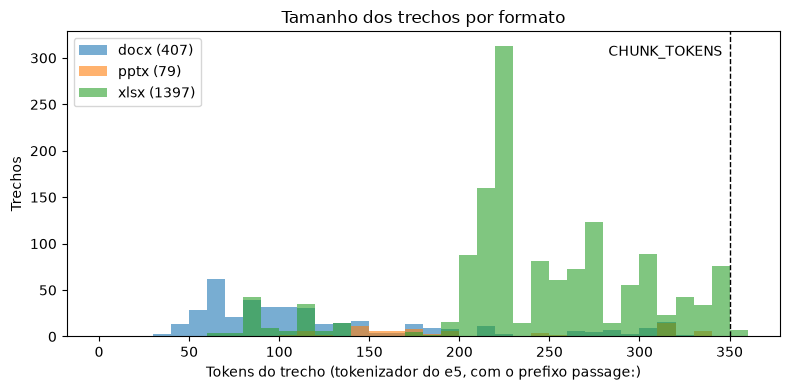

,count,mean,std,min,25%,50%,75%,max
formato,,,,,,,,
docx,407.0,126.3,76.2,38.0,69.0,101.0,147.5,334.0
pptx,79.0,204.3,76.0,74.0,144.0,177.0,286.5,333.0
xlsx,1397.0,242.6,60.4,66.0,214.0,228.0,278.0,350.0


In [12]:
figura, eixo = plt.subplots(figsize=(8, 4))
for nome_formato, grupo in trechos.groupby("formato"):
    eixo.hist(grupo["tokens"], bins=range(0, 361, 10), alpha=0.6, label=f"{nome_formato} ({len(grupo)})")
eixo.axvline(settings.chunk_tokens, color="black", linestyle="--", linewidth=1)
eixo.text(settings.chunk_tokens - 4, eixo.get_ylim()[1] * 0.92, "CHUNK_TOKENS", ha="right")
eixo.set_xlabel("Tokens do trecho (tokenizador do e5, com o prefixo passage:)")
eixo.set_ylabel("Trechos")
eixo.set_title("Tamanho dos trechos por formato")
eixo.legend()
figura.tight_layout()
plt.show()
trechos.groupby("formato")["tokens"].describe().round(1)

Dois trechos de exemplo. Cada um abre com a **linha de contexto** (código, nome do projeto, documento e seção, aba ou slide), que entra no vetor de propósito. Na prosa do termo de abertura, o corpo segue em parágrafos. Na planilha, cada linha de tabela vira `COLUNA: valor`, sem as células vazias, e nunca é cortada entre trechos.

In [13]:
def mostrar(trecho_id: str) -> None:
    linha = trechos.loc[trecho_id]
    print(f"── {trecho_id} · {linha['localizador']} · {linha['tokens']} tokens · perfis: {linha['perfis']}")
    print(linha["texto"][:900] + ("…" if len(linha["texto"]) > 900 else ""))
    print()


mostrar(trechos[trechos["documento_id"] == "PRJ-2024-018_TAP"].index[1])
mostrar(trechos[(trechos["documento_id"] == "PRJ-2024-018_RSK")].index[0])

── PRJ-2024-018_TAP#0002 · 1. IDENTIFICAÇÃO · 133 tokens · perfis: diretoria, lider_projeto, membro_equipe
PRJ-2024-018 · Modernização do Trecho Sul — Termo de Abertura v3 (22/08/2025)
1. IDENTIFICAÇÃO
Tipo: Modernização de Sistemas
Linha/Ativo: 1-Azul
Subportfólio: sistemas
Diretoria demandante: Engenharia e Planejamento
Patrocinador: Marcos Vinícius Quintanilha — Diretor de Engenharia e Planejamento
Gerente do projeto: Adriana Peçanha Vilar — M-48213
Áreas envolvidas: Gerência Jurídica; Gerência de Portfólio (GPM); Gerência de Engenharia de Sistemas

── PRJ-2024-018_RSK#0001 · aba Riscos e Problemas · 343 tokens · perfis: diretoria, lider_projeto, membro_equipe
PRJ-2024-018 · Modernização do Trecho Sul — Registro de riscos e problemas (posição em 11/08/2026)
aba Riscos e Problemas
ID_ITEM: RSK-PRJ-2024-018-001 | ID_PROJETO: PRJ-2024-018 | TIPO: Problema | DESCRICAO: Variação cambial sobre equipamentos importados pode consumir a reserva de contingência do contrato de fornecimento (fre

## 5. Embeddings (9.4.3.5)

O encoder é o `intfloat/multilingual-e5-large`, compartilhado com o classificador de intenções. Uma amostra fixa de 32 trechos, escolhida pelo hash do identificador, é vetorizada com `codificar_passagens`, a função que a ingestão usa. O encoder já foi carregado pela divisão da seção 4, que conta tokens com o tokenizador dele, e por isso a vazão medida aqui é só a da vetorização, verificação do teto incluída.

In [14]:
amostra = trechos.loc[sorted(trechos.index, key=lambda i: hashlib.md5(i.encode()).hexdigest())[:32]]

inicio = time.perf_counter()
vetores_amostra = np.array(codificar_passagens(amostra["texto"].tolist()))
duracao = time.perf_counter() - inicio

normas = np.linalg.norm(vetores_amostra, axis=1)
pd.DataFrame(
    [
        ("trechos vetorizados", len(vetores_amostra)),
        ("dimensão", vetores_amostra.shape[1]),
        ("dimensão esperada pelo índice (DIMENSAO)", DIMENSAO),
        ("norma mínima / máxima", f"{normas.min():.6f} / {normas.max():.6f}"),
        ("vazão em CPU (trechos/s)", round(len(vetores_amostra) / duracao, 2)),
        ("tokens médios da amostra", round(amostra["tokens"].mean(), 1)),
    ],
    columns=["medida", "valor"],
).set_index("medida")

,valor
medida,
trechos vetorizados,32
dimensão,1024
dimensão esperada pelo índice (DIMENSAO),1024
norma mínima / máxima,1.000000 / 1.000000
vazão em CPU (trechos/s),1.37
tokens médios da amostra,199.5


**Os prefixos não são detalhe.** A família e5 foi treinada com `query: ` na pergunta e `passage: ` no trecho. O prefixo errado não levanta erro, mas muda o vetor e, com ele, o *score*. A tabela compara a similaridade entre a pergunta R01 da bancada e o trecho do termo de abertura que traz o custo, com cada combinação de prefixos:

In [15]:
pergunta_r01 = next(c for c in bancada.carregar() if c.id == "R01").pergunta
trecho_custo = trechos[
    (trechos["documento_id"] == "PRJ-2024-018_TAP") & trechos["texto"].str.contains("847.900.000")
].iloc[0]

combinacoes = {
    "query: / passage: (o da ingestão)": (PREFIXO_CONSULTA, PREFIXO_PASSAGEM),
    "passage: / passage:": (PREFIXO_PASSAGEM, PREFIXO_PASSAGEM),
    "query: / query:": (PREFIXO_CONSULTA, PREFIXO_CONSULTA),
    "sem prefixo": ("", ""),
}
linhas = []
for rotulo, (na_pergunta, no_trecho) in combinacoes.items():
    a, b = embeddings._codificar([na_pergunta + pergunta_r01, no_trecho + trecho_custo["texto"]])
    linhas.append((rotulo, round(float(np.dot(a, b)), 4)))
print(f"pergunta: {pergunta_r01}\ntrecho:   {trecho_custo.name}\n")
pd.DataFrame(linhas, columns=["prefixos (pergunta / trecho)", "cosseno"]).set_index("prefixos (pergunta / trecho)")

pergunta: Qual é o custo total estimado no termo de abertura da Modernização do Trecho Sul?
trecho:   PRJ-2024-018_TAP#0010



,cosseno
prefixos (pergunta / trecho),
query: / passage: (o da ingestão),0.8941
passage: / passage:,0.8745
query: / query:,0.8754
sem prefixo,0.8892


**O teto de 512 tokens vira erro, e não truncamento.** Um texto maior seria cortado em silêncio pelo encoder. A fachada recusa o lote e nomeia o culpado:

In [16]:
try:
    codificar_passagens(["Cronograma físico-financeiro consolidado do projeto. " * 80])
except ErroTruncamento as erro:
    print(f"ErroTruncamento: {erro}")

## 6. Índice vetorial no Pinecone (9.4.4)

O índice guarda vetor, identificador e três campos de filtro, e nunca o texto. Os identificadores são determinísticos (`documento_id#ordinal`), então cada vetor da amostra pode ser buscado pelo id e comparado com o que acabou de ser calculado. Cosseno 1,0 quer dizer que o índice contém exatamente a vetorização dos trechos da seção 4.

In [17]:
indice = pinecone.Pinecone(api_key=settings.pinecone_api_key).Index(settings.pinecone_index)
estatisticas = indice.describe_index_stats()
print(f"índice {settings.pinecone_index}: dimensão {estatisticas.dimension}, métrica cosseno")
print(f"vetores no namespace {NAMESPACE!r}: {estatisticas.namespaces[NAMESPACE].vector_count}\n")

guardados = indice.fetch(ids=list(amostra.index), namespace=NAMESPACE).vectors
cossenos = [
    float(np.dot(vetor, np.array(guardados[trecho_id].values)))
    for trecho_id, vetor in zip(amostra.index, vetores_amostra)
    if trecho_id in guardados
]
print(f"vetores da amostra encontrados no índice: {len(cossenos)} de {len(amostra)}")
print(f"cosseno entre o recalculado e o gravado: mín {min(cossenos):.6f} · máx {max(cossenos):.6f}\n")

exemplo = amostra.index[0]
print(f"metadado de {exemplo}: {dict(guardados[exemplo].metadata)}")

índice portfolio-metro: dimensão 1024, métrica cosseno
vetores no namespace 'bancada-eduardo': 1883



vetores da amostra encontrados no índice: 32 de 32
cosseno entre o recalculado e o gravado: mín 1.000000 · máx 1.000000

metadado de PRJ-2024-018_FIN#0093: {'documento_id': 'PRJ-2024-018_FIN', 'perfis': ['diretoria', 'lider_projeto', 'membro_equipe'], 'projeto': 'PRJ-2024-018'}


**O filtro de permissão vai na consulta, nunca depois dela.** A mesma pergunta sobre o projeto Restrito, feita por três escopos. O filtro que cada escopo manda ao Pinecone está na primeira coluna, e só a diretoria recebe trechos do PRJ-2026-012:

In [18]:
pergunta_restrita = "Qual o orçamento aprovado do projeto Expansão Leste?"
vetor_restrito = codificar_consulta(pergunta_restrita)
escopos = {
    "diretoria": Escopo(Perfil.DIRETORIA),
    "lider_projeto do PRJ-2024-018": Escopo(Perfil.LIDER_PROJETO, frozenset({"PRJ-2024-018"})),
    "membro_equipe do PRJ-2026-012": Escopo(Perfil.MEMBRO_EQUIPE, frozenset({"PRJ-2026-012"})),
}
linhas = []
for rotulo, escopo in escopos.items():
    resposta = indice.query(
        vector=list(vetor_restrito),
        top_k=settings.rag_top_k,
        filter=filtro_de_escopo(escopo),
        namespace=NAMESPACE,
        include_metadata=True,
    )
    projetos = [m["metadata"]["projeto"] for m in resposta["matches"]]
    linhas.append(
        {
            "escopo": rotulo,
            "filtro na consulta": filtro_de_escopo(escopo),
            "trechos do PRJ-2026-012 entre os k": projetos.count("PRJ-2026-012"),
            "documentos recuperados": ", ".join(dict.fromkeys(m["metadata"]["documento_id"] for m in resposta["matches"])),
        }
    )
pd.DataFrame(linhas).set_index("escopo")

,filtro na consulta,trechos do PRJ-2026-012 entre os k,documentos recuperados
escopo,,,
diretoria,{'perfis': {'$in': ['diretoria']}},1,"PORT-2026_PORTF, PRJ-2025-064_RSP_2026-06, PRJ-2024-018_RSP_2026-08, PRJ-2024-018_RSP_2026-07"
lider_projeto do PRJ-2024-018,"{'perfis': {'$in': ['lider_projeto']}, 'projeto': {'$in': ['__transversal__', 'PRJ-2024-018']}}",0,"PRJ-2024-018_RSP_2026-08, PRJ-2024-018_RSP_2026-07, PORT-2026_BAL_2026-06, PORT-2026_PORTF, PORT-2026_BAL_2026-07"
membro_equipe do PRJ-2026-012,"{'perfis': {'$in': ['membro_equipe']}, 'projeto': {'$in': ['__transversal__', 'PRJ-2026-012']}}",0,"IN-11-2024_NI, NOR-00-223_NI"


## 7. Recuperação nas 26 perguntas da bancada (9.4.5.1 e 9.4.6)

Cada pergunta de `dados/bancada-rag.csv` passa pelo `Recuperador` de produção, com o perfil e os projetos de quem pergunta: e5 com `query:`, busca filtrada no Pinecone, texto lido do PostgreSQL e conferência da permissão. Nenhum modelo de linguagem é chamado nesta seção. O recall e o vazamento usam `bancada.avaliar_recuperacao`, a mesma regra da bancada completa.

In [19]:
casos = bancada.carregar()
recuperador = montar_recuperador(sessao)

recuperacoes = {}
linhas = []
for caso in casos:
    recuperacao = await recuperador.recuperar(caso.pergunta, caso.escopo)
    recuperacoes[caso.id] = recuperacao
    avaliado = bancada.avaliar_recuperacao(caso, recuperacao)
    linhas.append(
        {
            "id": caso.id,
            "caso": caso.caso,
            "perfil": caso.perfil.value,
            "espera": "resposta" if caso.espera_resposta else "abstenção",
            "esperados": "; ".join("|".join(g) for g in caso.documentos_esperados) or "—",
            "recuperados": ", ".join(avaliado.documentos_recuperados) or "—",
            "recall": avaliado.recall,
            "score do topo": recuperacao.trechos[0].score if recuperacao.trechos else None,
            "vazou": avaliado.projeto_proibido,
            "sem texto": recuperacao.sem_texto,
            "fora do escopo": recuperacao.fora_do_escopo,
        }
    )
por_caso = pd.DataFrame(linhas).set_index("id")
por_caso.drop(columns=["sem texto", "fora do escopo"]).round(3)

,caso,perfil,espera,esperados,recuperados,recall,score do topo,vazou
id,,,,,,,,
R01,documental,lider_projeto,resposta,PRJ-2024-018_TAP,"PRJ-2024-018_TAP, PRJ-2024-018_RSP_2026-07, PRJ-2024-018_RSP_2026-08",1.0,0.894,False
R02,documental,lider_projeto,resposta,PRJ-2026-077_TAP,"PRJ-2026-077_TAP, PRJ-2026-077_RSP_2026-08, PORT-2026_PORTF, PRJ-2026-077_RSK",1.0,0.873,False
R03,documental,lider_projeto,resposta,PRJ-2026-001_TAP,PRJ-2026-001_TAP,1.0,0.896,False
R04,documental,membro_equipe,resposta,PRJ-2024-018_TAP,"PRJ-2024-018_TAP, PRJ-2024-018_CRON",1.0,0.858,False
R05,documental,membro_equipe,resposta,PRJ-2025-064_TAP,"PRJ-2025-064_TAP, PRJ-2025-064_RSP_2026-06",1.0,0.861,False
R06,documental,diretoria,resposta,PRJ-2025-088_TEP,"PRJ-2025-088_TEP, PORT-2026_PORTF, PRJ-2025-088_RSK",1.0,0.877,False
R07,documental,diretoria,resposta,PRJ-2023-089_TEP,PRJ-2023-089_TEP,1.0,0.877,False
R08,documental,lider_projeto,resposta,PRJ-2025-042_RSP_2026-08|PORT-2026_PORTF,"PRJ-2025-042_RSP_2026-07, PRJ-2025-042_RSP_2026-08, PRJ-2025-042_RSP_2026-06",1.0,0.893,False
R09,documental,lider_projeto,resposta,PRJ-2025-042_RSP_2026-07,"PRJ-2025-042_RSP_2026-07, PRJ-2025-042_RSP_2026-06, PRJ-2025-042_RSP_2026-08",1.0,0.896,False


In [20]:
recall_medio = por_caso["recall"].dropna().mean()
pd.DataFrame(
    [
        ("recall@k médio", f"{recall_medio:.3f}", f"≥ {bancada.META_RECALL:.2f}"),
        ("casos com recall < 1", ", ".join(por_caso.index[por_caso["recall"] < 1]) or "nenhum", "—"),
        ("vazamento na recuperação", ", ".join(por_caso.index[por_caso["vazou"]]) or "nenhum", "zero"),
        ("vetores sem texto no PostgreSQL", int(por_caso["sem texto"].sum()), "zero"),
        ("trechos descartados pela conferência de permissão", int(por_caso["fora do escopo"].sum()), "zero"),
    ],
    columns=["indicador", "medido", "meta"],
).set_index("indicador")

,medido,meta
indicador,,
recall@k médio,0.975,≥ 0.90
casos com recall < 1,R19,—
vazamento na recuperação,nenhum,zero
vetores sem texto no PostgreSQL,0,zero
trechos descartados pela conferência de permissão,0,zero


**O corte de *score* não separa os casos.** O *score* do trecho mais similar dos casos que esperam resposta se sobrepõe ao dos que esperam abstenção, e o `RAG_SCORE_MINIMO` fica abaixo das duas faixas. Quem decide a abstenção é a geração (9.4.6).

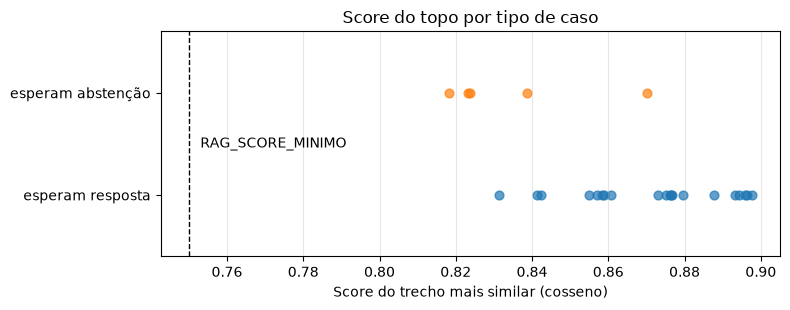

,count,min,mean,max
espera,,,,
abstenção,5.0,0.818,0.835,0.870
resposta,20.0,0.831,0.871,0.898


In [21]:
figura, eixo = plt.subplots(figsize=(8, 3.2))
for posicao, (rotulo, filtro) in enumerate(
    [("esperam resposta", por_caso["espera"] == "resposta"), ("esperam abstenção", por_caso["espera"] == "abstenção")]
):
    valores = por_caso.loc[filtro, "score do topo"].dropna()
    eixo.scatter(valores, [posicao] * len(valores), alpha=0.7, s=40, label=f"{rotulo} ({len(valores)})")
eixo.axvline(settings.rag_score_minimo, color="black", linestyle="--", linewidth=1)
eixo.text(settings.rag_score_minimo + 0.003, 0.5, "RAG_SCORE_MINIMO", va="center")
eixo.set_yticks([0, 1], ["esperam resposta", "esperam abstenção"])
eixo.set_ylim(-0.6, 1.6)
eixo.set_xlabel("Score do trecho mais similar (cosseno)")
eixo.set_title("Score do topo por tipo de caso")
eixo.grid(axis="x", alpha=0.3)
figura.tight_layout()
plt.show()
por_caso.groupby("espera")["score do topo"].describe()[["count", "min", "mean", "max"]].round(3)

### Trechos recuperados por pergunta

Os `k` trechos que chegariam ao modelo, na ordem de similaridade, com documento, localizador, *score* e o começo do texto. Um ✔ marca o trecho de um documento esperado, e um ✖, o de um projeto proibido ao escopo.

In [22]:
def resumo(texto: str, largura: int = 260) -> str:
    corpo = " ".join(texto.split())
    return corpo[:largura] + ("…" if len(corpo) > largura else "")


partes = []
for caso in casos:
    esperados = {d for grupo in caso.documentos_esperados for d in grupo}
    escopo = caso.perfil.value + (f" ({', '.join(sorted(caso.projetos))})" if caso.projetos else "")
    partes.append(f"#### {caso.id} · {caso.caso} · {escopo}\n\n**{caso.pergunta}**\n")
    recuperacao = recuperacoes[caso.id]
    if recuperacao.vazia:
        partes.append("_Nenhum trecho acima do corte de score._\n")
        continue
    for posicao, trecho in enumerate(recuperacao.trechos, start=1):
        marca = "✔ " if trecho.documento_id in esperados else ("✖ " if trecho.projeto in caso.projetos_proibidos else "")
        partes.append(
            f"{posicao}. {marca}`{trecho.documento_id}` · {trecho.localizador} · score {trecho.score:.3f}  \n"
            f"   {resumo(trecho.texto)}"
        )
    partes.append("")
display(Markdown("\n".join(partes)))

#### R01 · documental · lider_projeto (PRJ-2024-018)

**Qual é o custo total estimado no termo de abertura da Modernização do Trecho Sul?**

1. ✔ `PRJ-2024-018_TAP` · 8. CUSTO · score 0.894  
   PRJ-2024-018 · Modernização do Trecho Sul — Termo de Abertura v3 (22/08/2025) 8. CUSTO Total estimado: R$ 847.900.000,00 Natureza: CAPEX Fonte: Tesouro Estadual Ano: Valor 2024: R$ 131.570.689,66 2025: R$ 292.379.310,34 2026: R$ 292.379.310,34 2027: R$ 131.570…
2. `PRJ-2024-018_RSP_2026-07` · 10. SITUAÇÃO FINANCEIRA · score 0.867  
   PRJ-2024-018 · Modernização do Trecho Sul — Relatório de Status — julho/2026 10. SITUAÇÃO FINANCEIRA Faturas em aberto: 6 — R$ 31.095.688,10 Vencidas: 6 — R$ 31.095.688,10
3. `PRJ-2024-018_RSP_2026-08` · 10. SITUAÇÃO FINANCEIRA · score 0.865  
   PRJ-2024-018 · Modernização do Trecho Sul — Relatório de Status — agosto/2026 10. SITUAÇÃO FINANCEIRA Faturas em aberto: 7 — R$ 34.557.891,23 Vencidas: 6 — R$ 31.095.688,10
4. ✔ `PRJ-2024-018_TAP` · 3. OBJETIVO · score 0.864  
   PRJ-2024-018 · Modernização do Trecho Sul — Termo de Abertura v3 (22/08/2025) 3. OBJETIVO Executar substituição do sistema de sinalização, renovação da rede aérea e readequação das subestações do trecho sul da Linha 1-Azul, entre as estações Jabaquara e Paraís…
5. ✔ `PRJ-2024-018_TAP` · 1. IDENTIFICAÇÃO · score 0.863  
   PRJ-2024-018 · Modernização do Trecho Sul — Termo de Abertura v3 (22/08/2025) 1. IDENTIFICAÇÃO Tipo: Modernização de Sistemas Linha/Ativo: 1-Azul Subportfólio: sistemas Diretoria demandante: Engenharia e Planejamento Patrocinador: Marcos Vinícius Quintanilha —…

#### R02 · documental · lider_projeto (PRJ-2026-077)

**Quem é o gerente do projeto Terminal Jabaquara?**

1. ✔ `PRJ-2026-077_TAP` · 15. APROVAÇÕES · score 0.873  
   PRJ-2026-077 · Terminal Jabaquara — Termo de Abertura v1 (16/02/2026) 15. APROVAÇÕES Nome: Renata Sanguinetti Alencar | Cargo: Diretora de Operações | Data: 16/02/2026 | Situação: Aprovado Nome: Danilo Aragão Bittencourt | Cargo: Gerente do projeto | Data: 13/…
2. `PRJ-2026-077_RSP_2026-08` · Cabeçalho do documento · score 0.871  
   PRJ-2026-077 · Terminal Jabaquara — Relatório de Status — agosto/2026 Cabeçalho do documento Projeto: Terminal Jabaquara Código: PRJ-2026-077 Emitido em: 02/09/2026 Gerente: Danilo Aragão Bittencourt
3. ✔ `PRJ-2026-077_TAP` · 1. IDENTIFICAÇÃO · score 0.862  
   PRJ-2026-077 · Terminal Jabaquara — Termo de Abertura v1 (16/02/2026) 1. IDENTIFICAÇÃO Tipo: Renovação de Ativos Linha/Ativo: 1-Azul Subportfólio: obras civis Diretoria demandante: Operações Patrocinador: Renata Sanguinetti Alencar — Diretora de Operações Gere…
4. `PORT-2026_PORTF` · aba Portfolio · score 0.860  
   Consolidado do portfólio (posição em 31/08/2026) aba Portfolio ID_PROJETO: PRJ-2026-077 | NOME_PROJETO: Terminal Jabaquara | TIPO_PROJETO: Renovação de Ativos | LINHA: 1-Azul | SUBPORTFOLIO: obras civis | DIRETORIA_DEMANDANTE: Operações | PATROCINADOR: Renata …
5. `PRJ-2026-077_RSK` · aba Riscos e Problemas · score 0.857  
   PRJ-2026-077 · Terminal Jabaquara — Registro de riscos e problemas (posição em 18/08/2026) aba Riscos e Problemas ID_ITEM: RSK-PRJ-2026-077-011 | ID_PROJETO: PRJ-2026-077 | TIPO: Risco | DESCRICAO: Acidente em frente de obra confinada pode gerar interdição da …

#### R03 · documental · lider_projeto (PRJ-2026-001)

**Quando termina o projeto Estação Morumbi segundo o termo de abertura?**

1. ✔ `PRJ-2026-001_TAP` · 7. PRAZO · score 0.896  
   PRJ-2026-001 · Estação Morumbi — Termo de Abertura v1 (12/01/2026) 7. PRAZO Início: 12/01/2026 Término: 31/08/2028 Duração: 32 meses
2. ✔ `PRJ-2026-001_TAP` · 3. OBJETIVO · score 0.888  
   PRJ-2026-001 · Estação Morumbi — Termo de Abertura v1 (12/01/2026) 3. OBJETIVO Executar construção da estação Morumbi da Linha 17-Ouro, com integração à malha de transporte da região e obras de acesso viário.
3. ✔ `PRJ-2026-001_TAP` · Cabeçalho do documento · score 0.880  
   PRJ-2026-001 · Estação Morumbi — Termo de Abertura v1 (12/01/2026) Cabeçalho do documento Projeto: Estação Morumbi Código: PRJ-2026-001 Versão: v1 Data: 12/01/2026
4. ✔ `PRJ-2026-001_TAP` · 6. ENTREGAS E MARCOS PRINCIPAIS · score 0.876  
   PRJ-2026-001 · Estação Morumbi — Termo de Abertura v1 (12/01/2026) 6. ENTREGAS E MARCOS PRINCIPAIS ID do marco: MRC-PRJ-2026-001-01 | Descrição: Aprovação do projeto básico | Data prevista: 18/04/2026 ID do marco: MRC-PRJ-2026-001-02 | Descrição: Emissão da li…
5. ✔ `PRJ-2026-001_TAP` · 16. HISTÓRICO DE VERSÕES · score 0.873  
   PRJ-2026-001 · Estação Morumbi — Termo de Abertura v1 (12/01/2026) 16. HISTÓRICO DE VERSÕES Versão: v1 | Data: 12/01/2026 | Autor: Cleide Marchetti Nunes | Alteração: Emissão inicial

#### R04 · documental · membro_equipe (PRJ-2024-018)

**O que ficou fora do escopo da Modernização do Trecho Sul?**

1. ✔ `PRJ-2024-018_TAP` · 5. ESCOPO PRELIMINAR · score 0.858  
   PRJ-2024-018 · Modernização do Trecho Sul — Termo de Abertura v3 (22/08/2025) 5. ESCOPO PRELIMINAR Incluso: - Substituição integral do sistema de sinalização entre Jabaquara e Paraíso - Renovação da rede aérea de tração do trecho - Readequação de quatro subest…
2. ✔ `PRJ-2024-018_TAP` · 3. OBJETIVO · score 0.851  
   PRJ-2024-018 · Modernização do Trecho Sul — Termo de Abertura v3 (22/08/2025) 3. OBJETIVO Executar substituição do sistema de sinalização, renovação da rede aérea e readequação das subestações do trecho sul da Linha 1-Azul, entre as estações Jabaquara e Paraís…
3. `PRJ-2024-018_CRON` · aba Marcos · score 0.848  
   PRJ-2024-018 · Modernização do Trecho Sul — Cronograma de marcos e atividades (posição em 11/08/2026) aba Marcos ID_MARCO: MRC-PRJ-2024-018-09 | ID_PROJETO: PRJ-2024-018 | DESCRICAO_MARCO: Homologação pela área de operação | TIPO: Aprovação externa | DATA_BASE…
4. ✔ `PRJ-2024-018_TAP` · 2. JUSTIFICATIVA / SITUAÇÃO ATUAL · score 0.847  
   PRJ-2024-018 · Modernização do Trecho Sul — Termo de Abertura v3 (22/08/2025) 2. JUSTIFICATIVA / SITUAÇÃO ATUAL O sistema atualmente em operação encontra-se em fase avançada do seu ciclo de vida, com fabricante já sem oferta de peças de reposição para parte do…
5. ✔ `PRJ-2024-018_TAP` · 1. IDENTIFICAÇÃO · score 0.847  
   PRJ-2024-018 · Modernização do Trecho Sul — Termo de Abertura v3 (22/08/2025) 1. IDENTIFICAÇÃO Tipo: Modernização de Sistemas Linha/Ativo: 1-Azul Subportfólio: sistemas Diretoria demandante: Engenharia e Planejamento Patrocinador: Marcos Vinícius Quintanilha —…

#### R05 · documental · membro_equipe (PRJ-2025-064)

**Qual é o objetivo do projeto Via Permanente Trecho Norte?**

1. ✔ `PRJ-2025-064_TAP` · Cabeçalho do documento · score 0.861  
   PRJ-2025-064 · Via Permanente Trecho Norte — Termo de Abertura v1 (14/04/2025) Cabeçalho do documento Projeto: Via Permanente Trecho Norte Código: PRJ-2025-064 Versão: v1 Data: 14/04/2025
2. ✔ `PRJ-2025-064_TAP` · 3. OBJETIVO · score 0.858  
   PRJ-2025-064 · Via Permanente Trecho Norte — Termo de Abertura v1 (14/04/2025) 3. OBJETIVO Executar substituição de trilhos, dormentes e aparelhos de mudança de via no trecho norte da Linha 1-Azul, executada em janelas noturnas sem interrupção da operação come…
3. ✔ `PRJ-2025-064_TAP` · 4. ALINHAMENTO ESTRATÉGICO · score 0.855  
   PRJ-2025-064 · Via Permanente Trecho Norte — Termo de Abertura v1 (14/04/2025) 4. ALINHAMENTO ESTRATÉGICO Objetivo estratégico: Elevar a confiabilidade e a disponibilidade dos sistemas Ação do PPA: 5013 — Renovação e manutenção de ativos operacionais Indicador…
4. `PRJ-2025-064_RSP_2026-06` · Cabeçalho do documento · score 0.854  
   PRJ-2025-064 · Via Permanente Trecho Norte — Relatório de Status — junho/2026 Cabeçalho do documento Projeto: Via Permanente Trecho Norte Código: PRJ-2025-064 Emitido em: 04/07/2026 Gerente: Gisele Amanajás Ribeiro
5. ✔ `PRJ-2025-064_TAP` · 13. PARTES INTERESSADAS · score 0.848  
   PRJ-2025-064 · Via Permanente Trecho Norte — Termo de Abertura v1 (14/04/2025) 13. PARTES INTERESSADAS Nome: Adriana Peçanha Vilar | Organização: Metrô — Engenharia e Planejamento | Papel: Patrocinador | Influência: 2 Nome: Danilo Aragão Bittencourt | Organiza…

#### R06 · documental · diretoria

**Por que o projeto Subestação Vila Sônia foi cancelado?**

1. ✔ `PRJ-2025-088_TEP` · 2. RESUMO DO PROJETO · score 0.877  
   PRJ-2025-088 · Subestação Vila Sônia — Termo de Encerramento (07/06/2026) 2. RESUMO DO PROJETO Implantação de subestação primária para reforço do fornecimento de energia de tração no trecho oeste da Linha 4-Amarela. O projeto foi interrompido com 27.0% de avan…
2. ✔ `PRJ-2025-088_TEP` · 8. TRANSFERÊNCIA PARA OPERAÇÃO · score 0.872  
   PRJ-2025-088 · Subestação Vila Sônia — Termo de Encerramento (07/06/2026) 8. TRANSFERÊNCIA PARA OPERAÇÃO Não aplicável. O projeto foi cancelado antes da conclusão das entregas e não houve transferência de ativo para a operação.
3. ✔ `PRJ-2025-088_TEP` · 1. TIPO DE ENCERRAMENTO · score 0.863  
   PRJ-2025-088 · Subestação Vila Sônia — Termo de Encerramento (07/06/2026) 1. TIPO DE ENCERRAMENTO Tipo: Cancelamento Justificativa: O reestudo de carga conduzido após a primeira fase indicou que a margem de reserva pretendida seria alcançada por reconfiguração…
4. `PORT-2026_PORTF` · aba Portfolio · score 0.860  
   Consolidado do portfólio (posição em 31/08/2026) aba Portfolio ID_PROJETO: PRJ-2025-088 | NOME_PROJETO: Subestação Vila Sônia | TIPO_PROJETO: Eficiência Energética | LINHA: 4-Amarela (PPP) | SUBPORTFOLIO: sistemas | DIRETORIA_DEMANDANTE: Operações | PATROCINAD…
5. `PRJ-2025-088_RSK` · aba Riscos e Problemas · score 0.858  
   PRJ-2025-088 · Subestação Vila Sônia — Registro de riscos e problemas (posição em 28/08/2026) aba Riscos e Problemas ID_ITEM: RSK-PRJ-2025-088-010 | ID_PROJETO: PRJ-2025-088 | TIPO: Risco | DESCRICAO: Atraso na emissão de licença pelo órgão ambiental pode prov…

#### R07 · documental · diretoria

**Qual foi o desvio de custo da Reforma da Estação Central no encerramento?**

1. ✔ `PRJ-2023-089_TEP` · 3. RESULTADO VS. PLANEJADO · score 0.877  
   PRJ-2023-089 · Reforma da Estação Central — Termo de Encerramento (13/01/2025) 3. RESULTADO VS. PLANEJADO Dimensão: Prazo | Baseline: 29/11/2024 | Realizado: 20/12/2024 | Desvio: 21 dias Dimensão: Custo | Baseline: R$ 18.900.000,00 | Realizado: R$ 19.637.099,9…
2. ✔ `PRJ-2023-089_TEP` · 6. SITUAÇÃO CONTRATUAL · score 0.852  
   PRJ-2023-089 · Reforma da Estação Central — Termo de Encerramento (13/01/2025) 6. SITUAÇÃO CONTRATUAL ID do contrato: CTR-2023-470 | Situação: Encerrado | Saldo: R$ 5.166.900,01 | Garantias: Seguro-garantia — validade 14/03/2025
3. ✔ `PRJ-2023-089_TEP` · Cabeçalho do documento · score 0.844  
   PRJ-2023-089 · Reforma da Estação Central — Termo de Encerramento (13/01/2025) Cabeçalho do documento Projeto: Reforma da Estação Central Código: PRJ-2023-089 Data: 13/01/2025
4. ✔ `PRJ-2023-089_TEP` · 2. RESUMO DO PROJETO · score 0.843  
   PRJ-2023-089 · Reforma da Estação Central — Termo de Encerramento (13/01/2025) 2. RESUMO DO PROJETO Reforma de acabamentos, iluminação e sistema de ventilação da estação central da Linha 1-Azul. As entregas previstas foram concluídas e aceitas, com 8 marcos re…
5. ✔ `PRJ-2023-089_TEP` · 7. BENEFÍCIOS NA DATA DE ENCERRAMENTO · score 0.840  
   PRJ-2023-089 · Reforma da Estação Central — Termo de Encerramento (13/01/2025) 7. BENEFÍCIOS NA DATA DE ENCERRAMENTO ID: BEN-PRJ-2023-089-01 | Meta: 18 anos | Realizado ou previsto: 14.7 anos | Situação: Realizado | Medição futura: 20/12/2025 ID: BEN-PRJ-2023-…

#### R08 · documental · lider_projeto (PRJ-2025-042)

**Qual o farol geral do Sistema de Sinalização no relatório de status de agosto de 2026?**

1. `PRJ-2025-042_RSP_2026-07` · 1. PAINEL DE FARÓIS · score 0.893  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — julho/2026 1. PAINEL DE FARÓIS Geral: Vermelho Prazo: Vermelho Custo: Amarelo Escopo: Verde Tendência vs. mês anterior: Melhorou Justificativa:
2. ✔ `PRJ-2025-042_RSP_2026-08` · 1. PAINEL DE FARÓIS · score 0.892  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — agosto/2026 1. PAINEL DE FARÓIS Geral: Vermelho Prazo: Vermelho Custo: Amarelo Escopo: Verde Tendência vs. mês anterior: Melhorou Justificativa: Duas frentes permanecem paralisadas desde o mês anter…
3. ✔ `PRJ-2025-042_RSP_2026-08` · Cabeçalho do documento · score 0.887  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — agosto/2026 Cabeçalho do documento Projeto: Sistema de Sinalização Código: PRJ-2025-042 Emitido em: 01/09/2026 Gerente: Bruno Katayama Ferrari
4. `PRJ-2025-042_RSP_2026-06` · 1. PAINEL DE FARÓIS · score 0.886  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — junho/2026 1. PAINEL DE FARÓIS Geral: Vermelho Prazo: Vermelho Custo: Amarelo Escopo: Verde Tendência vs. mês anterior: Melhorou Justificativa: Duas frentes permanecem paralisadas desde o mês anteri…
5. `PRJ-2025-042_RSP_2026-07` · Cabeçalho do documento · score 0.880  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — julho/2026 Cabeçalho do documento Projeto: Sistema de Sinalização Código: PRJ-2025-042 Emitido em: 06/08/2026 Gerente: Bruno Katayama Ferrari

#### R09 · documental · lider_projeto (PRJ-2025-042)

**Qual foi o avanço físico realizado do Sistema de Sinalização no relatório de julho de 2026?**

1. ✔ `PRJ-2025-042_RSP_2026-07` · 2. AVANÇO · score 0.896  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — julho/2026 2. AVANÇO Físico previsto 35.1% | realizado 30.6% | desvio -4.5 p.p. Financeiro previsto 39.7% | realizado 35.2% Orçamento: aprovado R$ 312.400.000,00 | comprometido R$ 260.834.000,00 | r…
2. `PRJ-2025-042_RSP_2026-06` · 2. AVANÇO · score 0.890  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — junho/2026 2. AVANÇO Físico previsto 31.7% | realizado 28.9% | desvio -2.8 p.p. Financeiro previsto 38.8% | realizado 33.2% Orçamento: aprovado R$ 312.400.000,00 | comprometido R$ 260.834.000,00 | r…
3. `PRJ-2025-042_RSP_2026-08` · 2. AVANÇO · score 0.886  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — agosto/2026 2. AVANÇO Físico previsto 38.5% | realizado 32.3% | desvio -6.2 p.p. Financeiro previsto 39.4% | realizado 37.2% Orçamento: aprovado R$ 312.400.000,00 | comprometido R$ 260.834.000,00 | …
4. ✔ `PRJ-2025-042_RSP_2026-07` · Cabeçalho do documento · score 0.877  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — julho/2026 Cabeçalho do documento Projeto: Sistema de Sinalização Código: PRJ-2025-042 Emitido em: 06/08/2026 Gerente: Bruno Katayama Ferrari
5. ✔ `PRJ-2025-042_RSP_2026-07` · 1. PAINEL DE FARÓIS · score 0.877  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — julho/2026 1. PAINEL DE FARÓIS Geral: Vermelho Prazo: Vermelho Custo: Amarelo Escopo: Verde Tendência vs. mês anterior: Melhorou Justificativa:

#### R10 · documental · lider_projeto (PRJ-2025-042)

**Quais decisões estão pendentes no relatório de status de agosto do Sistema de Sinalização?**

1. ✔ `PRJ-2025-042_RSP_2026-08` · 1. PAINEL DE FARÓIS · score 0.876  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — agosto/2026 1. PAINEL DE FARÓIS Geral: Vermelho Prazo: Vermelho Custo: Amarelo Escopo: Verde Tendência vs. mês anterior: Melhorou Justificativa: Duas frentes permanecem paralisadas desde o mês anter…
2. ✔ `PRJ-2025-042_RSP_2026-08` · 4. PREVISTO PARA O PRÓXIMO PERÍODO · score 0.875  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — agosto/2026 4. PREVISTO PARA O PRÓXIMO PERÍODO - Conclusão do relatório de compatibilização eletromagnética. - Conclusão da adequação de acessibilidade da segunda estação. - Emissão do termo de rece…
3. ✔ `PRJ-2025-042_RSP_2026-08` · 9. DECISÕES REQUERIDAS · score 0.873  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — agosto/2026 9. DECISÕES REQUERIDAS Assunto: Repactuação do cronograma contratual | Decisor: GPM | Prazo: 27/09/2026 | Opções: Aditivo de prazo | Aplicação de penalidade Assunto: Ampliação do turno d…
4. ✔ `PRJ-2025-042_RSP_2026-08` · 3. REALIZADO NO PERÍODO · score 0.871  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — agosto/2026 3. REALIZADO NO PERÍODO - Conclusão da montagem do trecho intermediário da frente norte. - Atualização do cadastro de interferências com base na sondagem complementar. - Treinamento das …
5. `PORT-2026_BAL_2026-08` · slide 13: Decisões requeridas · score 0.871  
   Balanço do Portfólio — agosto/2026 slide 13: Decisões requeridas Submetidas à deliberação da diretoria Assunto: Destinação do escopo remanescente de subestação | Opções: Reincluir no portfólio | Incorporar ao programa de manutenção | Recomendação do GPM: Incor…

#### R11 · documental · lider_projeto (PRJ-2025-042)

**Qual o valor das faturas vencidas do Sistema de Sinalização no relatório de agosto de 2026?**

1. ✔ `PRJ-2025-042_RSP_2026-08` · 10. SITUAÇÃO FINANCEIRA · score 0.898  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — agosto/2026 10. SITUAÇÃO FINANCEIRA Faturas em aberto: 3 — R$ 15.113.706,46 Vencidas: 3 — R$ 15.113.706,46
2. `PRJ-2025-042_RSP_2026-07` · 10. SITUAÇÃO FINANCEIRA · score 0.890  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — julho/2026 10. SITUAÇÃO FINANCEIRA Faturas em aberto: 3 — R$ 15.113.706,46 Vencidas: 3 — R$ 15.113.706,46
3. `PRJ-2025-042_RSP_2026-06` · 10. SITUAÇÃO FINANCEIRA · score 0.888  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — junho/2026 10. SITUAÇÃO FINANCEIRA Faturas em aberto: 3 — R$ 15.113.706,46 Vencidas: 3 — R$ 15.113.706,46
4. ✔ `PRJ-2025-042_RSP_2026-08` · 2. AVANÇO · score 0.880  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — agosto/2026 2. AVANÇO Físico previsto 38.5% | realizado 32.3% | desvio -6.2 p.p. Financeiro previsto 39.4% | realizado 37.2% Orçamento: aprovado R$ 312.400.000,00 | comprometido R$ 260.834.000,00 | …
5. ✔ `PRJ-2025-042_RSP_2026-08` · Cabeçalho do documento · score 0.876  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — agosto/2026 Cabeçalho do documento Projeto: Sistema de Sinalização Código: PRJ-2025-042 Emitido em: 01/09/2026 Gerente: Bruno Katayama Ferrari

#### R12 · normativo · membro_equipe

**Até quando o gerente de projeto deve emitir o relatório de status mensal?**

1. ✔ `IN-04-2023_NI` · 5. RESPONSABILIDADES · score 0.888  
   Instrução de trabalho IN-04-2023 — Periodicidade e Conteúdo do Relatório de Status de Projeto (v2, vigência 12/06/2023) 5. RESPONSABILIDADES Papel: Responsabilidade Gerente de Projeto: Emitir o relatório até o quinto dia útil do mês subsequente ao de referênci…
2. ✔ `IN-04-2023_NI` · 4. DEFINIÇÕES · score 0.859  
   Instrução de trabalho IN-04-2023 — Periodicidade e Conteúdo do Relatório de Status de Projeto (v2, vigência 12/06/2023) 4. DEFINIÇÕES Termo: Definição Relatório de status: Documento mensal que reporta desempenho, riscos, problemas e decisões requeridas. Farol:…
3. ✔ `IN-04-2023_NI` · 8. ANEXOS E FORMULÁRIOS · score 0.858  
   Instrução de trabalho IN-04-2023 — Periodicidade e Conteúdo do Relatório de Status de Projeto (v2, vigência 12/06/2023) 8. ANEXOS E FORMULÁRIOS - Formulário de registro de demanda - Modelo de relatório de status - Planilha de registro de riscos e problemas
4. ✔ `IN-04-2023_NI` · 1. OBJETIVO · score 0.856  
   Instrução de trabalho IN-04-2023 — Periodicidade e Conteúdo do Relatório de Status de Projeto (v2, vigência 12/06/2023) 1. OBJETIVO Estabelecer a periodicidade, o conteúdo mínimo e o prazo de emissão do relatório de status dos projetos do portfólio.
5. ✔ `IN-04-2023_NI` · 7. CRITÉRIOS E ALÇADAS · score 0.856  
   Instrução de trabalho IN-04-2023 — Periodicidade e Conteúdo do Relatório de Status de Projeto (v2, vigência 12/06/2023) 7. CRITÉRIOS E ALÇADAS Critério: Farol diferente de Verde | Valor limite: Justificativa obrigatória | Instância: Gerente de Projeto Critério…

#### R13 · normativo · membro_equipe

**Quem aprova uma mudança com impacto de 15% no orçamento do projeto?**

1. ✔ `IN-11-2024_NI` · 7. CRITÉRIOS E ALÇADAS · score 0.831  
   Instrução de trabalho IN-11-2024 — Alçadas de Aprovação de Mudanças de Escopo, Prazo e Custo (v1, vigência 02/09/2024) 7. CRITÉRIOS E ALÇADAS Critério: Impacto até 2% do orçamento | Valor limite: Gerente de Projeto | Instância: Projeto Critério: Impacto de 2% …
2. ✔ `IN-11-2024_NI` · 6. PROCEDIMENTO · score 0.820  
   Instrução de trabalho IN-11-2024 — Alçadas de Aprovação de Mudanças de Escopo, Prazo e Custo (v1, vigência 02/09/2024) 6. PROCEDIMENTO 6.1 Solicitação Registro da mudança com justificativa e análise de impacto. Entrada: Necessidade identificada. Saída: Solicit…
3. ✔ `IN-11-2024_NI` · 1. OBJETIVO · score 0.820  
   Instrução de trabalho IN-11-2024 — Alçadas de Aprovação de Mudanças de Escopo, Prazo e Custo (v1, vigência 02/09/2024) 1. OBJETIVO Definir as instâncias competentes para aprovação de mudanças de escopo, prazo e custo nos projetos do portfólio.
4. ✔ `IN-11-2024_NI` · 4. DEFINIÇÕES · score 0.818  
   Instrução de trabalho IN-11-2024 — Alçadas de Aprovação de Mudanças de Escopo, Prazo e Custo (v1, vigência 02/09/2024) 4. DEFINIÇÕES Termo: Definição Mudança: Alteração formal de escopo, prazo ou custo em relação à baseline aprovada. Alçada: Limite de valor ou…
5. ✔ `IN-11-2024_NI` · 5. RESPONSABILIDADES · score 0.814  
   Instrução de trabalho IN-11-2024 — Alçadas de Aprovação de Mudanças de Escopo, Prazo e Custo (v1, vigência 02/09/2024) 5. RESPONSABILIDADES Papel: Responsabilidade Gerente de Projeto: Submeter a solicitação com análise de impacto nas três dimensões. Gerência d…

#### R14 · normativo · membro_equipe

**Que faixa de exposição classifica um risco como de nível Alto?**

1. ✔ `NOR-07-041_NI` · 7. CRITÉRIOS E ALÇADAS · score 0.857  
   Procedimento NOR-07-041 — Gestão de Riscos e Problemas em Projetos (v2, vigência 07/04/2025) 7. CRITÉRIOS E ALÇADAS Critério: Exposição de 1 a 6 | Valor limite: Nível Baixo | Instância: Projeto Critério: Exposição de 7 a 12 | Valor limite: Nível Médio | Instân…
2. ✔ `NOR-07-041_NI` · 4. DEFINIÇÕES · score 0.844  
   Procedimento NOR-07-041 — Gestão de Riscos e Problemas em Projetos (v2, vigência 07/04/2025) 4. DEFINIÇÕES Termo: Definição Risco: Evento incerto que, se ocorrer, afeta ao menos um objetivo do projeto. Problema: Risco materializado, cuja probabilidade deixou d…
3. ✔ `NOR-07-041_NI` · 5. RESPONSABILIDADES · score 0.806  
   Procedimento NOR-07-041 — Gestão de Riscos e Problemas em Projetos (v2, vigência 07/04/2025) 5. RESPONSABILIDADES Papel: Responsabilidade Gerente de Projeto: Manter o registro de riscos atualizado e revisá-lo, no mínimo, a cada 60 dias. Responsável pelo risco:…
4. ✔ `NOR-07-041_NI` · 6. PROCEDIMENTO · score 0.804  
   Procedimento NOR-07-041 — Gestão de Riscos e Problemas em Projetos (v2, vigência 07/04/2025) 6. PROCEDIMENTO 6.1 Identificação Registro do risco no formato causa, evento e efeito, com categoria atribuída. Entrada: Reunião de análise. Saída: Item registrado. Pr…
5. `NOR-12-008_NI` · 7. CRITÉRIOS E ALÇADAS · score 0.802  
   Norma interna NOR-12-008 — Classificação e Tratamento da Informação (v5, vigência 20/11/2023) 7. CRITÉRIOS E ALÇADAS Critério: Público | Valor limite: Divulgação irrestrita | Instância: Assuntos Corporativos Critério: Interno | Valor limite: Colaboradores da c…

#### R15 · normativo · lider_projeto (PRJ-2024-018)

**Qual o prazo para emitir o termo de encerramento de um projeto?**

1. ✔ `NOR-09-062_NI` · 5. RESPONSABILIDADES · score 0.875  
   Manual NOR-09-062 — Encerramento de Projetos e Realização de Benefícios (v2, vigência 26/02/2024) 5. RESPONSABILIDADES Papel: Responsabilidade Gerente de Projeto: Elaborar o Termo de Encerramento em até 60 dias do término das entregas. Área receptora: Confirma…
2. ✔ `NOR-09-062_NI` · 4. DEFINIÇÕES · score 0.873  
   Manual NOR-09-062 — Encerramento de Projetos e Realização de Benefícios (v2, vigência 26/02/2024) 4. DEFINIÇÕES Termo: Definição Termo de Encerramento: Documento que formaliza a conclusão do projeto e a transferência para operação. Benefício: Resultado mensurá…
3. ✔ `NOR-09-062_NI` · 7. CRITÉRIOS E ALÇADAS · score 0.868  
   Manual NOR-09-062 — Encerramento de Projetos e Realização de Benefícios (v2, vigência 26/02/2024) 7. CRITÉRIOS E ALÇADAS Critério: Prazo para emissão do termo | Valor limite: 60 dias do término | Instância: Gerente de Projeto Critério: Benefício com medição fu…
4. ✔ `NOR-00-223_NI` · 6. PROCEDIMENTO · score 0.848  
   Norma interna NOR-00-223 — Governança do Portfólio Corporativo de Projetos (v4, vigência 01/07/2024) 6. PROCEDIMENTO 6.1 Registro da demanda A área demandante submete a demanda ao GPM com justificativa, estimativa preliminar e vínculo estratégico. Entrada: For…
5. ✔ `NOR-09-062_NI` · 1. OBJETIVO · score 0.845  
   Manual NOR-09-062 — Encerramento de Projetos e Realização de Benefícios (v2, vigência 26/02/2024) 1. OBJETIVO Definir o procedimento de encerramento de projetos e o acompanhamento da realização dos benefícios previstos.

#### R16 · normativo · lider_projeto (PRJ-2025-042)

**Qual o limite de acréscimo acumulado em contratos pela norma de gestão contratual?**

1. ✔ `NOR-05-317_NI` · 7. CRITÉRIOS E ALÇADAS · score 0.880  
   Procedimento NOR-05-317 — Gestão Contratual e Limites de Aditivo (v3, vigência 10/03/2025) 7. CRITÉRIOS E ALÇADAS Critério: Acréscimo acumulado | Valor limite: Até 25% do valor atualizado | Instância: Gestor do contrato Critério: Acréscimo em reforma de edifíc…
2. ✔ `NOR-05-317_NI` · 1. OBJETIVO · score 0.870  
   Procedimento NOR-05-317 — Gestão Contratual e Limites de Aditivo (v3, vigência 10/03/2025) 1. OBJETIVO Estabelecer as regras de acompanhamento contratual, medição, ateste e controle dos limites legais de acréscimo.
3. ✔ `NOR-05-317_NI` · Cabeçalho do documento · score 0.860  
   Procedimento NOR-05-317 — Gestão Contratual e Limites de Aditivo (v3, vigência 10/03/2025) Cabeçalho do documento Título: Gestão Contratual e Limites de Aditivo Área emissora: Gerência de Portfólio (GPM) Versão: v3 Vigência: 10/03/2025 Revisão prevista: 10/03/…
4. ✔ `NOR-05-317_NI` · 2. ABRANGÊNCIA · score 0.856  
   Procedimento NOR-05-317 — Gestão Contratual e Limites de Aditivo (v3, vigência 10/03/2025) 2. ABRANGÊNCIA Aplica-se aos contratos vinculados a projetos do portfólio.
5. ✔ `NOR-05-317_NI` · 3. DOCUMENTOS DE REFERÊNCIA · score 0.850  
   Procedimento NOR-05-317 — Gestão Contratual e Limites de Aditivo (v3, vigência 10/03/2025) 3. DOCUMENTOS DE REFERÊNCIA - Lei 14.133/2021, art. 125 - NOR-00-223

#### R17 · normativo · membro_equipe

**Qual a diferença entre risco e problema?**

1. ✔ `NOR-07-041_NI` · 4. DEFINIÇÕES · score 0.855  
   Procedimento NOR-07-041 — Gestão de Riscos e Problemas em Projetos (v2, vigência 07/04/2025) 4. DEFINIÇÕES Termo: Definição Risco: Evento incerto que, se ocorrer, afeta ao menos um objetivo do projeto. Problema: Risco materializado, cuja probabilidade deixou d…
2. ✔ `NOR-07-041_NI` · 1. OBJETIVO · score 0.831  
   Procedimento NOR-07-041 — Gestão de Riscos e Problemas em Projetos (v2, vigência 07/04/2025) 1. OBJETIVO Estabelecer o processo de identificação, análise, tratamento e monitoramento de riscos e problemas nos projetos do portfólio.
3. ✔ `NOR-07-041_NI` · 8. ANEXOS E FORMULÁRIOS · score 0.824  
   Procedimento NOR-07-041 — Gestão de Riscos e Problemas em Projetos (v2, vigência 07/04/2025) 8. ANEXOS E FORMULÁRIOS - Formulário de registro de demanda - Modelo de relatório de status - Planilha de registro de riscos e problemas
4. ✔ `NOR-07-041_NI` · 6. PROCEDIMENTO · score 0.820  
   Procedimento NOR-07-041 — Gestão de Riscos e Problemas em Projetos (v2, vigência 07/04/2025) 6. PROCEDIMENTO 6.1 Identificação Registro do risco no formato causa, evento e efeito, com categoria atribuída. Entrada: Reunião de análise. Saída: Item registrado. Pr…
5. ✔ `NOR-07-041_NI` · Cabeçalho do documento · score 0.820  
   Procedimento NOR-07-041 — Gestão de Riscos e Problemas em Projetos (v2, vigência 07/04/2025) Cabeçalho do documento Título: Gestão de Riscos e Problemas em Projetos Área emissora: Gerência de Portfólio (GPM) Versão: v2 Vigência: 07/04/2025 Revisão prevista: 07…

#### R18 · normativo · membro_equipe

**Quem pode acessar um documento classificado como Restrito?**

1. ✔ `NOR-12-008_NI` · 4. DEFINIÇÕES · score 0.842  
   Norma interna NOR-12-008 — Classificação e Tratamento da Informação (v5, vigência 20/11/2023) 4. DEFINIÇÕES Termo: Definição Classificação: Atribuição de categoria de sigilo a um documento, conforme o dano potencial de sua divulgação. Perfil de acesso: Conjunt…
2. ✔ `NOR-12-008_NI` · 6. PROCEDIMENTO · score 0.819  
   Norma interna NOR-12-008 — Classificação e Tratamento da Informação (v5, vigência 20/11/2023) 6. PROCEDIMENTO 6.1 Atribuição Definição da categoria no momento da criação do documento. Entrada: Documento em elaboração. Saída: Documento classificado. Prazo: cont…
3. ✔ `NOR-12-008_NI` · 7. CRITÉRIOS E ALÇADAS · score 0.817  
   Norma interna NOR-12-008 — Classificação e Tratamento da Informação (v5, vigência 20/11/2023) 7. CRITÉRIOS E ALÇADAS Critério: Público | Valor limite: Divulgação irrestrita | Instância: Assuntos Corporativos Critério: Interno | Valor limite: Colaboradores da c…
4. ✔ `NOR-12-008_NI` · 3. DOCUMENTOS DE REFERÊNCIA · score 0.817  
   Norma interna NOR-12-008 — Classificação e Tratamento da Informação (v5, vigência 20/11/2023) 3. DOCUMENTOS DE REFERÊNCIA - Lei 12.527/2011 — Acesso à informação - ISO/IEC 27001:2022 - Política de Segurança da Informação
5. ✔ `NOR-12-008_NI` · 8. ANEXOS E FORMULÁRIOS · score 0.809  
   Norma interna NOR-12-008 — Classificação e Tratamento da Informação (v5, vigência 20/11/2023) 8. ANEXOS E FORMULÁRIOS - Formulário de registro de demanda - Modelo de relatório de status - Planilha de registro de riscos e problemas

#### R19 · distribuida · lider_projeto (PRJ-2025-042)

**Até quando o relatório de status deve ser emitido pela norma, e em que data foi emitido o relatório de agosto do Sistema de Sinalização?**

1. ✔ `PRJ-2025-042_RSP_2026-08` · Cabeçalho do documento · score 0.859  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — agosto/2026 Cabeçalho do documento Projeto: Sistema de Sinalização Código: PRJ-2025-042 Emitido em: 01/09/2026 Gerente: Bruno Katayama Ferrari
2. ✔ `PRJ-2025-042_RSP_2026-08` · 4. PREVISTO PARA O PRÓXIMO PERÍODO · score 0.857  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — agosto/2026 4. PREVISTO PARA O PRÓXIMO PERÍODO - Conclusão do relatório de compatibilização eletromagnética. - Conclusão da adequação de acessibilidade da segunda estação. - Emissão do termo de rece…
3. ✔ `PRJ-2025-042_RSP_2026-08` · 8. MUDANÇAS NO PERÍODO · score 0.856  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — agosto/2026 8. MUDANÇAS NO PERÍODO Nenhuma mudança submetida no período.
4. `PRJ-2025-042_RSP_2026-07` · Cabeçalho do documento · score 0.852  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — julho/2026 Cabeçalho do documento Projeto: Sistema de Sinalização Código: PRJ-2025-042 Emitido em: 06/08/2026 Gerente: Bruno Katayama Ferrari
5. `PRJ-2025-042_RSP_2026-07` · 9. DECISÕES REQUERIDAS · score 0.850  
   PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — julho/2026 9. DECISÕES REQUERIDAS Assunto: Liberação de janela operacional adicional aos sábados | Decisor: Comitê | Prazo: 01/09/2026 | Opções: Conceder | Manter a programação vigente

#### R20 · abstencao · diretoria

**Qual é o salário do gerente do projeto Terminal Jabaquara?**

1. `PRJ-2026-077_TAP` · 8. CUSTO · score 0.870  
   PRJ-2026-077 · Terminal Jabaquara — Termo de Abertura v1 (16/02/2026) 8. CUSTO Total estimado: R$ 38.600.000,00 Natureza: CAPEX Fonte: Recursos Próprios Ano: Valor 2026: R$ 19.300.000,00 2027: R$ 19.300.000,00 Total: R$ 38.600.000,00
2. `PRJ-2026-077_RSP_2026-08` · Cabeçalho do documento · score 0.869  
   PRJ-2026-077 · Terminal Jabaquara — Relatório de Status — agosto/2026 Cabeçalho do documento Projeto: Terminal Jabaquara Código: PRJ-2026-077 Emitido em: 02/09/2026 Gerente: Danilo Aragão Bittencourt
3. `PORT-2026_PORTF` · aba Portfolio · score 0.866  
   Consolidado do portfólio (posição em 31/08/2026) aba Portfolio ID_PROJETO: PRJ-2026-077 | NOME_PROJETO: Terminal Jabaquara | TIPO_PROJETO: Renovação de Ativos | LINHA: 1-Azul | SUBPORTFOLIO: obras civis | DIRETORIA_DEMANDANTE: Operações | PATROCINADOR: Renata …
4. `PRJ-2026-077_TAP` · 15. APROVAÇÕES · score 0.863  
   PRJ-2026-077 · Terminal Jabaquara — Termo de Abertura v1 (16/02/2026) 15. APROVAÇÕES Nome: Renata Sanguinetti Alencar | Cargo: Diretora de Operações | Data: 16/02/2026 | Situação: Aprovado Nome: Danilo Aragão Bittencourt | Cargo: Gerente do projeto | Data: 13/…
5. `PRJ-2026-077_RSK` · aba Riscos e Problemas · score 0.861  
   PRJ-2026-077 · Terminal Jabaquara — Registro de riscos e problemas (posição em 18/08/2026) aba Riscos e Problemas ID_ITEM: RSK-PRJ-2026-077-011 | ID_PROJETO: PRJ-2026-077 | TIPO: Risco | DESCRICAO: Acidente em frente de obra confinada pode gerar interdição da …

#### R21 · abstencao · diretoria

**Qual a previsão de inauguração da Linha 20-Rosa?**

1. `PRJ-2025-190_TAP` · 6. ENTREGAS E MARCOS PRINCIPAIS · score 0.839  
   PRJ-2025-190 · Acessibilidade Linha 4 — Termo de Abertura v1 (03/11/2025) 6. ENTREGAS E MARCOS PRINCIPAIS ID do marco: MRC-PRJ-2025-190-01 | Descrição: Aprovação do projeto de acessibilidade | Data prevista: 24/12/2025 ID do marco: MRC-PRJ-2025-190-02 | Descri…
2. `PRJ-2026-001_TAP` · 3. OBJETIVO · score 0.837  
   PRJ-2026-001 · Estação Morumbi — Termo de Abertura v1 (12/01/2026) 3. OBJETIVO Executar construção da estação Morumbi da Linha 17-Ouro, com integração à malha de transporte da região e obras de acesso viário.
3. `PRJ-2026-001_TAP` · 1. IDENTIFICAÇÃO · score 0.837  
   PRJ-2026-001 · Estação Morumbi — Termo de Abertura v1 (12/01/2026) 1. IDENTIFICAÇÃO Tipo: Expansão de Rede Linha/Ativo: 17-Ouro Subportfólio: expansão Diretoria demandante: Engenharia e Planejamento Patrocinador: Marcos Vinícius Quintanilha — Diretor de Engenh…
4. `PRJ-2025-190_CRON` · aba Marcos · score 0.834  
   PRJ-2025-190 · Acessibilidade Linha 4 — Cronograma de marcos e atividades (posição em 06/08/2026) aba Marcos ID_MARCO: MRC-PRJ-2025-190-03 | ID_PROJETO: PRJ-2025-190 | DESCRICAO_MARCO: Conclusão das adequações da primeira estação | TIPO: Entrega física | DATA_…
5. `PRJ-2025-190_TAP` · 8. CUSTO · score 0.831  
   PRJ-2025-190 · Acessibilidade Linha 4 — Termo de Abertura v1 (03/11/2025) 8. CUSTO Total estimado: R$ 24.150.000,00 Natureza: CAPEX Fonte: PPP/Concessão Ano: Valor 2025: R$ 12.075.000,00 2026: R$ 12.075.000,00 Total: R$ 24.150.000,00

#### R22 · abstencao · membro_equipe

**O que o PMBOK recomenda para o cálculo do valor agregado de um projeto?**

1. `NOR-00-223_NI` · 3. DOCUMENTOS DE REFERÊNCIA · score 0.823  
   Norma interna NOR-00-223 — Governança do Portfólio Corporativo de Projetos (v4, vigência 01/07/2024) 3. DOCUMENTOS DE REFERÊNCIA - Lei 14.133/2021 - PMBOK Guide, 7ª edição - ISO 21500:2021 — Gerenciamento de projetos - NOR-01-105 — Critérios de priorização
2. `NOR-01-105_NI` · 7. CRITÉRIOS E ALÇADAS · score 0.816  
   Norma interna NOR-01-105 — Critérios de Priorização e Seleção de Projetos (v3, vigência 15/01/2025) 7. CRITÉRIOS E ALÇADAS Critério: Aderência estratégica | Valor limite: Peso 30% | Instância: Comitê de Investimentos Critério: Benefício operacional esperado | …
3. `NOR-00-223_NI` · 7. CRITÉRIOS E ALÇADAS · score 0.811  
   Norma interna NOR-00-223 — Governança do Portfólio Corporativo de Projetos (v4, vigência 01/07/2024) 7. CRITÉRIOS E ALÇADAS Critério: Porte Estruturante | Valor limite: Acima de R$ 500 milhões | Instância: Diretoria Colegiada Critério: Porte Grande | Valor lim…
4. `IN-11-2024_NI` · 7. CRITÉRIOS E ALÇADAS · score 0.806  
   Instrução de trabalho IN-11-2024 — Alçadas de Aprovação de Mudanças de Escopo, Prazo e Custo (v1, vigência 02/09/2024) 7. CRITÉRIOS E ALÇADAS Critério: Impacto até 2% do orçamento | Valor limite: Gerente de Projeto | Instância: Projeto Critério: Impacto de 2% …
5. `NOR-01-105_NI` · 4. DEFINIÇÕES · score 0.806  
   Norma interna NOR-01-105 — Critérios de Priorização e Seleção de Projetos (v3, vigência 15/01/2025) 4. DEFINIÇÕES Termo: Definição Aderência estratégica: Grau de contribuição do projeto para os objetivos do mapa estratégico. Índice de priorização: Valor compos…

#### R23 · abstencao · diretoria

**Qual é a capital da Austrália?**

_Nenhum trecho acima do corte de score._

#### R24 · permissao · lider_projeto (PRJ-2024-018)

**Qual o orçamento aprovado do projeto Expansão Leste?**

1. `PRJ-2024-018_RSP_2026-08` · 2. AVANÇO · score 0.824  
   PRJ-2024-018 · Modernização do Trecho Sul — Relatório de Status — agosto/2026 2. AVANÇO Físico previsto 54.8% | realizado 46.4% | desvio -8.4 p.p. Financeiro previsto 45.5% | realizado 40.5% Orçamento: aprovado R$ 847.900.000,00 | comprometido R$ 756.504.000,0…
2. `PRJ-2024-018_RSP_2026-07` · 2. AVANÇO · score 0.821  
   PRJ-2024-018 · Modernização do Trecho Sul — Relatório de Status — julho/2026 2. AVANÇO Físico previsto 51.2% | realizado 44.8% | desvio -6.4 p.p. Financeiro previsto 42.8% | realizado 39.1% Orçamento: aprovado R$ 847.900.000,00 | comprometido R$ 756.504.000,00…
3. `PORT-2026_BAL_2026-06` · slide 4: Execução orçamentária · score 0.812  
   Balanço do Portfólio — junho/2026 slide 4: Execução orçamentária Aprovado, comprometido e realizado acumulados, por subportfólio Gráfico — Aprovado (R$ mi): expansão: 2264.5; manutenção: 158; material rodante: 1240; obras civis: 422.9; sistemas: 1200.2 Gráfico…
4. `PORT-2026_PORTF` · aba Portfolio · score 0.811  
   Consolidado do portfólio (posição em 31/08/2026) aba Portfolio ID_PROJETO: PRJ-2024-018 | NOME_PROJETO: Modernização do Trecho Sul | TIPO_PROJETO: Modernização de Sistemas | LINHA: 1-Azul | SUBPORTFOLIO: sistemas | DIRETORIA_DEMANDANTE: Engenharia e Planejamen…
5. `PORT-2026_BAL_2026-07` · slide 4: Execução orçamentária · score 0.810  
   Balanço do Portfólio — julho/2026 slide 4: Execução orçamentária Aprovado, comprometido e realizado acumulados, por subportfólio Gráfico — Aprovado (R$ mi): expansão: 2264.5; manutenção: 158; material rodante: 1240; obras civis: 422.9; sistemas: 1200.2 Gráfico…

#### R25 · permissao · diretoria

**Qual o orçamento aprovado do projeto Expansão Leste?**

1. ✔ `PORT-2026_PORTF` · aba Portfolio · score 0.841  
   Consolidado do portfólio (posição em 31/08/2026) aba Portfolio ID_PROJETO: PRJ-2026-012 | NOME_PROJETO: Expansão Leste | TIPO_PROJETO: Expansão de Rede | LINHA: 2-Verde | SUBPORTFOLIO: expansão | DIRETORIA_DEMANDANTE: Presidência | GERENTE_PROJETO: Ivone Barce…
2. `PRJ-2025-064_RSP_2026-06` · 2. AVANÇO · score 0.828  
   PRJ-2025-064 · Via Permanente Trecho Norte — Relatório de Status — junho/2026 2. AVANÇO Físico previsto 51.1% | realizado 46.3% | desvio -4.8 p.p. Financeiro previsto 44.4% | realizado 42.0% Orçamento: aprovado R$ 96.800.000,00 | comprometido R$ 102.063.000,00…
3. `PRJ-2024-018_RSP_2026-08` · 2. AVANÇO · score 0.824  
   PRJ-2024-018 · Modernização do Trecho Sul — Relatório de Status — agosto/2026 2. AVANÇO Físico previsto 54.8% | realizado 46.4% | desvio -8.4 p.p. Financeiro previsto 45.5% | realizado 40.5% Orçamento: aprovado R$ 847.900.000,00 | comprometido R$ 756.504.000,0…
4. ✔ `PORT-2026_PORTF` · aba Portfolio · score 0.822  
   Consolidado do portfólio (posição em 31/08/2026) aba Portfolio ID_PROJETO: PRJ-2024-052 | NOME_PROJETO: Duplicação do Trecho Oeste | TIPO_PROJETO: Expansão de Rede | LINHA: 3-Vermelha | SUBPORTFOLIO: expansão | DIRETORIA_DEMANDANTE: Engenharia e Planejamento |…
5. `PRJ-2024-018_RSP_2026-07` · 2. AVANÇO · score 0.821  
   PRJ-2024-018 · Modernização do Trecho Sul — Relatório de Status — julho/2026 2. AVANÇO Físico previsto 51.2% | realizado 44.8% | desvio -6.4 p.p. Financeiro previsto 42.8% | realizado 39.1% Orçamento: aprovado R$ 847.900.000,00 | comprometido R$ 756.504.000,00…

#### R26 · permissao · membro_equipe (PRJ-2024-031)

**Qual o avanço físico realizado do Monotrilho Ouro no relatório de agosto de 2026?**

1. `IN-04-2023_NI` · 6. PROCEDIMENTO · score 0.818  
   Instrução de trabalho IN-04-2023 — Periodicidade e Conteúdo do Relatório de Status de Projeto (v2, vigência 12/06/2023) 6. PROCEDIMENTO 6.1 Coleta Levantamento do avanço físico e financeiro do período. Entrada: Medições e apontamentos. Saída: Dados consolidado…
2. `NOR-09-062_NI` · Cabeçalho do documento · score 0.805  
   Manual NOR-09-062 — Encerramento de Projetos e Realização de Benefícios (v2, vigência 26/02/2024) Cabeçalho do documento Título: Encerramento de Projetos e Realização de Benefícios Área emissora: Gerência de Portfólio (GPM) Versão: v2 Vigência: 26/02/2024 Revi…
3. `IN-04-2023_NI` · 3. DOCUMENTOS DE REFERÊNCIA · score 0.800  
   Instrução de trabalho IN-04-2023 — Periodicidade e Conteúdo do Relatório de Status de Projeto (v2, vigência 12/06/2023) 3. DOCUMENTOS DE REFERÊNCIA - NOR-00-223 — Governança do portfólio
4. `NOR-09-062_NI` · 9. HISTÓRICO DE REVISÕES · score 0.799  
   Manual NOR-09-062 — Encerramento de Projetos e Realização de Benefícios (v2, vigência 26/02/2024) 9. HISTÓRICO DE REVISÕES Versão: v1 | Data: 02/01/2023 | Alteração: Emissão inicial Versão: v2 | Data: 26/02/2024 | Alteração: Revisão de conteúdo e atualização d…
5. `IN-04-2023_NI` · Cabeçalho do documento · score 0.799  
   Instrução de trabalho IN-04-2023 — Periodicidade e Conteúdo do Relatório de Status de Projeto (v2, vigência 12/06/2023) Cabeçalho do documento Título: Periodicidade e Conteúdo do Relatório de Status de Projeto Área emissora: Gerência de Portfólio (GPM) Versão:…


## 8. Bancada completa, com geração (9.4.6)

`bancada.executar` roda os mesmos 26 casos pelo fluxo inteiro: recuperação, montagem do prompt, modelo de geração e interpretação das citações. É a mesma função do `python -m app.rag.bancada`. Cada caso faz uma chamada ao modelo, com pausa de 4 s entre casos.

Antes de gastar, o saldo da conta do OpenRouter é conferido pelo *endpoint* `/credits`, que não custa nada.

In [23]:
if settings.llm_backend == "openrouter":
    creditos = httpx.get(
        "https://openrouter.ai/api/v1/credits",
        headers={"Authorization": f"Bearer {settings.openrouter_api_key}"},
        timeout=20,
    ).json()["data"]
    saldo = creditos["total_credits"] - creditos["total_usage"]
    print(f"saldo da conta OpenRouter antes da bancada: US$ {saldo:.2f}")
    assert saldo > 1, "saldo insuficiente para a bancada"

saldo da conta OpenRouter antes da bancada: US$ 12.41


In [24]:
inicio = time.perf_counter()
avaliacoes = await bancada.executar(montar_fluxo(sessao), casos)
print(f"bancada em {time.perf_counter() - inicio:.0f} s\n")
print(
    bancada.relatorio(
        avaliacoes,
        f"Bancada do RAG · {len(casos)} casos · namespace {NAMESPACE!r} · "
        f"modelo {settings.llm_backend}/{modelo_geracao} · k={settings.rag_top_k} · "
        f"score_minimo={settings.rag_score_minimo}\n",
    )
)

bancada em 315 s

Bancada do RAG · 26 casos · namespace 'bancada-eduardo' · modelo openrouter/google/gemini-3.5-flash · k=5 · score_minimo=0.75

=== Metas da seção 5.1 ===
  recall@k                           ATINGIDA  alvo 0.90 · medido 0.975
  abstenção correta                  ATINGIDA  alvo 0.80 · medido 1.000
  acerto de conteúdo                 ATINGIDA  alvo 0.80 · medido 0.950   (não pactuada)
  vazamento de permissão             nenhum
  abstenções indevidas               0
  respostas sem citação válida       0

=== Por caso ===
  R01 documental  ok    esperado responder respondida       recall=1.00 topo=0.894 7097 ms
  R02 documental  ok    esperado responder respondida       recall=1.00 topo=0.873 6921 ms
  R03 documental  ok    esperado responder respondida       recall=1.00 topo=0.896 6194 ms
  R04 documental  ok    esperado responder respondida       recall=1.00 topo=0.858 13041 ms
  R05 documental  ok    esperado responder respondida       recall=1.00 topo=0.861 6658 ms

In [25]:
resumo_bancada = bancada.resumir(avaliacoes)
validas = [a for a in avaliacoes if a.erro is None]
respondiveis = [a for a in validas if a.caso.espera_resposta]
nao_respondiveis = [a for a in validas if not a.caso.espera_resposta]


def fracao(medido, acertos, total) -> str:
    return "—" if medido is None else f"{medido:.3f} ({acertos} de {total})"


metricas = pd.DataFrame(
    [
        ("Recall@k", f"≥ {bancada.META_RECALL:.2f}", f"{resumo_bancada.recall_medio:.3f}"),
        (
            "Abstenção correta",
            f"≥ {bancada.META_ABSTENCAO:.2f}",
            fracao(resumo_bancada.abstencao_correta, sum(bool(a.abstencao_correta) for a in nao_respondiveis), len(nao_respondiveis)),
        ),
        (
            "Acerto de conteúdo",
            f"≥ {bancada.META_ACERTO_CONTEUDO:.2f}, não pactuada",
            fracao(resumo_bancada.acerto_conteudo, sum(bool(a.conteudo_ok) for a in respondiveis), len(respondiveis)),
        ),
        ("Vazamento", "zero", ", ".join(resumo_bancada.vazamentos) or "nenhum"),
        ("Abstenção indevida", "—", resumo_bancada.falsas_abstencoes),
        ("Resposta sem citação válida", "—", resumo_bancada.nao_fundamentadas),
        ("Falha do modelo (fora da conta)", "—", ", ".join(resumo_bancada.falhas_do_modelo) or "nenhuma"),
    ],
    columns=["indicador", "meta", "medido"],
).set_index("indicador")
metricas

,meta,medido
indicador,,
Recall@k,≥ 0.90,0.975
Abstenção correta,≥ 0.80,1.000 (6 de 6)
Acerto de conteúdo,"≥ 0.80, não pactuada",0.950 (19 de 20)
Vazamento,zero,nenhum
Abstenção indevida,—,0
Resposta sem citação válida,—,0
Falha do modelo (fora da conta),—,nenhuma


O recall da bancada completa tem de ser o da seção 7: a recuperação é a mesma, e o modelo só entra depois dela.

In [26]:
recall_completa = {a.caso.id: a.recall for a in validas if a.recall is not None}
recall_so_recuperacao = por_caso["recall"].dropna().to_dict()
assert recall_completa == {k: v for k, v in recall_so_recuperacao.items() if k in recall_completa}
print("recall por caso idêntico entre a seção 7 e a bancada completa")

recall por caso idêntico entre a seção 7 e a bancada completa


### Respostas ao lado das fontes citadas

É o material da revisão de fidelidade, que a bancada não mede automaticamente: cada resposta e os trechos que ela cita, como o `--saida` do comando escreve.

In [27]:
display(Markdown(bancada.detalhe_markdown(avaliacoes).replace("# Bancada do RAG", "#### Bancada do RAG", 1).replace("\n## ", "\n#### ")))

#### Bancada do RAG — respostas para revisão de fidelidade

#### R01 — Qual é o custo total estimado no termo de abertura da Modernização do Trecho Sul?

Perfil `lider_projeto`, projetos PRJ-2024-018 · situação `respondida`

> O custo total estimado no termo de abertura para o projeto PRJ-2024-018, Modernização do Trecho Sul, é de R$ 847.900.000,00 [1].

**[1]** PRJ-2024-018_TAP_v3_20250822.docx · 8. CUSTO

```text
PRJ-2024-018 · Modernização do Trecho Sul — Termo de Abertura v3 (22/08/2025) 8. CUSTO Total estimado: R$ 847.900.000,00 Natureza: CAPEX Fonte: Tesouro Estadual Ano: Valor 2024: R$ 131.570.689,66 2025: R$ 292.379.310,34 2026: R$ 292.379.310,34 2027: R$ 131.570.689,66 Total: R$ 847.900.000,00
```

#### R02 — Quem é o gerente do projeto Terminal Jabaquara?

Perfil `lider_projeto`, projetos PRJ-2026-077 · situação `respondida`

> O gerente do projeto PRJ-2026-077, Terminal Jabaquara, é Danilo Aragão Bittencourt [1], [2], [3], [4].

**[1]** PRJ-2026-077_TAP_v1_20260216.docx · 15. APROVAÇÕES

```text
PRJ-2026-077 · Terminal Jabaquara — Termo de Abertura v1 (16/02/2026) 15. APROVAÇÕES Nome: Renata Sanguinetti Alencar | Cargo: Diretora de Operações | Data: 16/02/2026 | Situação: Aprovado Nome: Danilo Aragão Bittencourt | Cargo: Gerente do projeto | Data: 13/02/2026 | Situação: Elaborado
```

**[2]** PRJ-2026-077_RSP_v1_20260828.docx · Cabeçalho do documento

```text
PRJ-2026-077 · Terminal Jabaquara — Relatório de Status — agosto/2026 Cabeçalho do documento Projeto: Terminal Jabaquara Código: PRJ-2026-077 Emitido em: 02/09/2026 Gerente: Danilo Aragão Bittencourt
```

**[3]** PRJ-2026-077_TAP_v1_20260216.docx · 1. IDENTIFICAÇÃO

```text
PRJ-2026-077 · Terminal Jabaquara — Termo de Abertura v1 (16/02/2026) 1. IDENTIFICAÇÃO Tipo: Renovação de Ativos Linha/Ativo: 1-Azul Subportfólio: obras civis Diretoria demandante: Operações Patrocinador: Renata Sanguinetti Alencar — Diretora de Operações Gerente do projeto: Danilo Aragão Bittencourt — M-56018 Áreas envolvidas: Gerência de Manutenção de Via; Gerência de Engenharia de Sistemas; Gerência de Obras Civis; Gerência Jurídica
```

**[4]** PORT-2026_PORTF_v1_20260831.xlsx · aba Portfolio

```text
Consolidado do portfólio (posição em 31/08/2026) aba Portfolio ID_PROJETO: PRJ-2026-077 | NOME_PROJETO: Terminal Jabaquara | TIPO_PROJETO: Renovação de Ativos | LINHA: 1-Azul | SUBPORTFOLIO: obras civis | DIRETORIA_DEMANDANTE: Operações | PATROCINADOR: Renata Sanguinetti Alencar | GERENTE_PROJETO: Danilo Aragão Bittencourt | FASE: Execução | FAROL_GERAL: Amarelo | FAROL_PRAZO: Verde | FAROL_CUSTO: Verde | FAROL_ESCOPO: Amarelo | PORTE: Médio | DATA_INICIO_BASELINE: 16/02/2026 | DATA_FIM_BASELINE: 31/03/2027 | DATA_FIM_PREVISTA_ATUAL: 28/04/2027 | DESVIO_PRAZO_DIAS: 28 | ORCAMENTO_APROVADO: 38600000 | VALOR_COMPROMETIDO: 38771000 | VALOR_REALIZADO: 7334000 | AVANCO_FISICO_PCT: 21 | AVANCO_FINANCEIRO_PCT: 18.2 | FONTE_RECURSO: Recursos Próprios | ACAO_PPA: 5013
```

#### R03 — Quando termina o projeto Estação Morumbi segundo o termo de abertura?

Perfil `lider_projeto`, projetos PRJ-2026-001 · situação `respondida`

> Segundo o termo de abertura, o projeto PRJ-2026-001, Estação Morumbi tem seu término previsto para 31/08/2028 [1].

**[1]** PRJ-2026-001_TAP_v1_20260112.docx · 7. PRAZO

```text
PRJ-2026-001 · Estação Morumbi — Termo de Abertura v1 (12/01/2026) 7. PRAZO Início: 12/01/2026 Término: 31/08/2028 Duração: 32 meses
```

#### R04 — O que ficou fora do escopo da Modernização do Trecho Sul?

Perfil `membro_equipe`, projetos PRJ-2024-018 · situação `respondida`

> Três itens constam como não inclusos no escopo do projeto [1]:
> • PRJ-2024-018, Modernização do Trecho Sul: as adequações em edificações de apoio administrativo estão fora do escopo [1].
> • PRJ-2024-018, Modernização do Trecho Sul: a aquisição de material rodante adicional não está inclusa [1].
> • PRJ-2024-018, Modernização do Trecho Sul: o desenvolvimento de sistemas não previstos na especificação funcional está excluído [1].

**[1]** PRJ-2024-018_TAP_v3_20250822.docx · 5. ESCOPO PRELIMINAR

```text
PRJ-2024-018 · Modernização do Trecho Sul — Termo de Abertura v3 (22/08/2025) 5. ESCOPO PRELIMINAR Incluso: - Substituição integral do sistema de sinalização entre Jabaquara e Paraíso - Renovação da rede aérea de tração do trecho - Readequação de quatro subestações retificadoras - Adequação do centro de controle às novas interfaces Não incluso: - Adequações em edificações de apoio administrativo. - Aquisição de material rodante adicional. - Desenvolvimento de sistemas não previstos na especificação funcional.
```

#### R05 — Qual é o objetivo do projeto Via Permanente Trecho Norte?

Perfil `membro_equipe`, projetos PRJ-2025-064 · situação `respondida`

> O objetivo do projeto PRJ-2025-064, Via Permanente Trecho Norte, é executar a substituição de trilhos, dormentes e aparelhos de mudança de via no trecho norte da Linha 1-Azul, executada em janelas noturnas sem interrupção da operação comercial [1].

**[1]** PRJ-2025-064_TAP_v1_20250414.docx · 3. OBJETIVO

```text
PRJ-2025-064 · Via Permanente Trecho Norte — Termo de Abertura v1 (14/04/2025) 3. OBJETIVO Executar substituição de trilhos, dormentes e aparelhos de mudança de via no trecho norte da Linha 1-Azul, executada em janelas noturnas sem interrupção da operação comercial.
```

#### R06 — Por que o projeto Subestação Vila Sônia foi cancelado?

Perfil `diretoria` · situação `respondida`

> PRJ-2025-088 - Subestação Vila Sônia: o cancelamento ocorreu porque um reestudo de carga indicou que a margem de reserva pretendida poderia ser obtida por meio da reconfiguração da rede existente a um custo menor, levando a diretoria a decidir pelo encerramento e pela incorporação do escopo restante ao programa de manutenção [1].

**[1]** PRJ-2025-088_TEP_v1_20260422.docx · 1. TIPO DE ENCERRAMENTO

```text
PRJ-2025-088 · Subestação Vila Sônia — Termo de Encerramento (07/06/2026) 1. TIPO DE ENCERRAMENTO Tipo: Cancelamento Justificativa: O reestudo de carga conduzido após a primeira fase indicou que a margem de reserva pretendida seria alcançada por reconfiguração da rede existente, a custo substancialmente menor. A diretoria determinou o cancelamento e a incorporação do escopo remanescente ao programa de manutenção.
```

#### R07 — Qual foi o desvio de custo da Reforma da Estação Central no encerramento?

Perfil `diretoria` · situação `respondida`

> No encerramento do projeto PRJ-2023-089, Reforma da Estação Central, o desvio na dimensão de custo foi de +3.9%, apresentando um valor realizado de R$ 19.637.099,99 em relação à baseline de R$ 18.900.000,00 [1].

**[1]** PRJ-2023-089_TEP_v1_20241220.docx · 3. RESULTADO VS. PLANEJADO

```text
PRJ-2023-089 · Reforma da Estação Central — Termo de Encerramento (13/01/2025) 3. RESULTADO VS. PLANEJADO Dimensão: Prazo | Baseline: 29/11/2024 | Realizado: 20/12/2024 | Desvio: 21 dias Dimensão: Custo | Baseline: R$ 18.900.000,00 | Realizado: R$ 19.637.099,99 | Desvio: +3.9% Dimensão: Escopo | Baseline: 100% das entregas | Realizado: 100.0% das entregas concluídas | Desvio: +0 p.p.
```

#### R08 — Qual o farol geral do Sistema de Sinalização no relatório de status de agosto de 2026?

Perfil `lider_projeto`, projetos PRJ-2025-042 · situação `respondida`

> PRJ-2025-042, Sistema de Sinalização: o farol geral do projeto no relatório de status de agosto de 2026 é Vermelho [1].

**[1]** PRJ-2025-042_RSP_v1_20260828.docx · 1. PAINEL DE FARÓIS

```text
PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — agosto/2026 1. PAINEL DE FARÓIS Geral: Vermelho Prazo: Vermelho Custo: Amarelo Escopo: Verde Tendência vs. mês anterior: Melhorou Justificativa: Duas frentes permanecem paralisadas desde o mês anterior, o que consumiu integralmente a folga do caminho crítico. O replanejamento foi submetido ao comitê e aguarda deliberação.
```

#### R09 — Qual foi o avanço físico realizado do Sistema de Sinalização no relatório de julho de 2026?

Perfil `lider_projeto`, projetos PRJ-2025-042 · situação `respondida`

> No relatório de julho de 2026 do projeto PRJ-2025-042, Sistema de Sinalização, o avanço físico realizado foi de 30.6% [1].

**[1]** Status Report Sinalizacao julho FINAL.docx · 2. AVANÇO

```text
PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — julho/2026 2. AVANÇO Físico previsto 35.1% | realizado 30.6% | desvio -4.5 p.p. Financeiro previsto 39.7% | realizado 35.2% Orçamento: aprovado R$ 312.400.000,00 | comprometido R$ 260.834.000,00 | realizado R$ 98.884.455,25
```

#### R10 — Quais decisões estão pendentes no relatório de status de agosto do Sistema de Sinalização?

Perfil `lider_projeto`, projetos PRJ-2025-042 · situação `respondida`

> No relatório de status de agosto do Sistema de Sinalização, foram encontradas as seguintes decisões pendentes:
> • PRJ-2025-042, Sistema de Sinalização: o replanejamento das frentes paralisadas foi submetido ao comitê e aguarda deliberação [1].
> • PRJ-2025-042, Sistema de Sinalização: a repactuação do cronograma contratual deve ser decidida pelo GPM até o prazo de 27/09/2026, tendo como opções o aditivo de prazo ou a aplicação de penalidade [2].
> • PRJ-2025-042, Sistema de Sinalização: a ampliação do turno de trabalho na frente crítica deve ser analisada pela Diretoria até o prazo de 09/10/2026, avaliando as opções de manter o turno atual ou ampliar com custo adicional [2].
> • projeto de sinalização: a repactuação de prazo apresenta como opções o aditivo de prazo de 210 dias ou a manutenção da baseline com penalidade, com recomendação do GPM para aditivo de prazo com revisão da baseline [3].

**[1]** PRJ-2025-042_RSP_v1_20260828.docx · 1. PAINEL DE FARÓIS

```text
PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — agosto/2026 1. PAINEL DE FARÓIS Geral: Vermelho Prazo: Vermelho Custo: Amarelo Escopo: Verde Tendência vs. mês anterior: Melhorou Justificativa: Duas frentes permanecem paralisadas desde o mês anterior, o que consumiu integralmente a folga do caminho crítico. O replanejamento foi submetido ao comitê e aguarda deliberação.
```

**[2]** PRJ-2025-042_RSP_v1_20260828.docx · 9. DECISÕES REQUERIDAS

```text
PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — agosto/2026 9. DECISÕES REQUERIDAS Assunto: Repactuação do cronograma contratual | Decisor: GPM | Prazo: 27/09/2026 | Opções: Aditivo de prazo | Aplicação de penalidade Assunto: Ampliação do turno de trabalho na frente crítica | Decisor: Diretoria | Prazo: 09/10/2026 | Opções: Manter o turno atual | Ampliar com custo adicional
```

**[3]** balanco portfolio agosto v2 (1).pptx · slide 13: Decisões requeridas

```text
Balanço do Portfólio — agosto/2026 slide 13: Decisões requeridas Submetidas à deliberação da diretoria Assunto: Destinação do escopo remanescente de subestação | Opções: Reincluir no portfólio | Incorporar ao programa de manutenção | Recomendação do GPM: Incorporar ao programa de manutenção Assunto: Repactuação de prazo do projeto de sinalização | Opções: Aditivo de prazo de 210 dias | Manutenção da baseline com penalidade | Recomendação do GPM: Aditivo de prazo, com revisão da baseline Assunto: Ampliação de turno na frente crítica do Trecho Sul | Opções: Manter turno atual | Ampliar com custo adicional estimado | Recomendação do GPM: Ampliar o turno pelo prazo de seis meses
```

#### R11 — Qual o valor das faturas vencidas do Sistema de Sinalização no relatório de agosto de 2026?

Perfil `lider_projeto`, projetos PRJ-2025-042 · situação `respondida`

> No projeto PRJ-2025-042, Sistema de Sinalização, o relatório de status de agosto de 2026 aponta o valor de R$ 15.113.706,46 para as 3 faturas vencidas [1].

**[1]** PRJ-2025-042_RSP_v1_20260828.docx · 10. SITUAÇÃO FINANCEIRA

```text
PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — agosto/2026 10. SITUAÇÃO FINANCEIRA Faturas em aberto: 3 — R$ 15.113.706,46 Vencidas: 3 — R$ 15.113.706,46
```

#### R12 — Até quando o gerente de projeto deve emitir o relatório de status mensal?

Perfil `membro_equipe` · situação `respondida`

> O gerente de projeto deve emitir o relatório até o quinto dia útil do mês subsequente ao de referência [1].

**[1]** IN-04-2023_NI_v2_20230612.docx · 5. RESPONSABILIDADES

```text
Instrução de trabalho IN-04-2023 — Periodicidade e Conteúdo do Relatório de Status de Projeto (v2, vigência 12/06/2023) 5. RESPONSABILIDADES Papel: Responsabilidade Gerente de Projeto: Emitir o relatório até o quinto dia útil do mês subsequente ao de referência. Gerência de Portfólio (GPM): Verificar a emissão e cobrar os relatórios em atraso.
```

#### R13 — Quem aprova uma mudança com impacto de 15% no orçamento do projeto?

Perfil `membro_equipe` · situação `respondida`

> Uma mudança com impacto de 15% no orçamento do projeto é aprovada pelo Comitê de Investimentos, que atua como a instância de aprovação para impactos na faixa de 10% a 25% [1].

**[1]** IN-11-2024_NI_v1_20240902.docx · 7. CRITÉRIOS E ALÇADAS

```text
Instrução de trabalho IN-11-2024 — Alçadas de Aprovação de Mudanças de Escopo, Prazo e Custo (v1, vigência 02/09/2024) 7. CRITÉRIOS E ALÇADAS Critério: Impacto até 2% do orçamento | Valor limite: Gerente de Projeto | Instância: Projeto Critério: Impacto de 2% a 10% | Valor limite: Gerência de Portfólio | Instância: GPM Critério: Impacto de 10% a 25% | Valor limite: Comitê de Investimentos | Instância: Comitê Critério: Impacto acima de 25% | Valor limite: Diretoria Colegiada | Instância: Diretoria Critério: Prorrogação superior a 180 dias | Valor limite: Diretoria Colegiada | Instância: Diretoria
```

#### R14 — Que faixa de exposição classifica um risco como de nível Alto?

Perfil `membro_equipe` · situação `respondida`

> A faixa de exposição que classifica um risco como de nível Alto é de 13 a 25 [1].

**[1]** NOR-07-041_NI_v2_20250407.docx · 7. CRITÉRIOS E ALÇADAS

```text
Procedimento NOR-07-041 — Gestão de Riscos e Problemas em Projetos (v2, vigência 07/04/2025) 7. CRITÉRIOS E ALÇADAS Critério: Exposição de 1 a 6 | Valor limite: Nível Baixo | Instância: Projeto Critério: Exposição de 7 a 12 | Valor limite: Nível Médio | Instância: Gerência de Portfólio Critério: Exposição de 13 a 25 | Valor limite: Nível Alto | Instância: Diretoria Critério: Risco de nível Alto sem plano | Valor limite: Não conformidade impeditiva | Instância: Gerência de Portfólio
```

#### R15 — Qual o prazo para emitir o termo de encerramento de um projeto?

Perfil `lider_projeto`, projetos PRJ-2024-018 · situação `respondida`

> O prazo para o Gerente de Projeto elaborar e emitir o Termo de Encerramento é de até 60 dias a partir do término das entregas [1] [2] [3].

**[1]** NOR-09-062_NI_v2_20240226.docx · 5. RESPONSABILIDADES

```text
Manual NOR-09-062 — Encerramento de Projetos e Realização de Benefícios (v2, vigência 26/02/2024) 5. RESPONSABILIDADES Papel: Responsabilidade Gerente de Projeto: Elaborar o Termo de Encerramento em até 60 dias do término das entregas. Área receptora: Confirmar o recebimento da documentação e do treinamento previstos. Gerência de Portfólio (GPM): Acompanhar a medição dos benefícios com data posterior ao encerramento.
```

**[2]** NOR-09-062_NI_v2_20240226.docx · 7. CRITÉRIOS E ALÇADAS

```text
Manual NOR-09-062 — Encerramento de Projetos e Realização de Benefícios (v2, vigência 26/02/2024) 7. CRITÉRIOS E ALÇADAS Critério: Prazo para emissão do termo | Valor limite: 60 dias do término | Instância: Gerente de Projeto Critério: Benefício com medição futura | Valor limite: Responsável nominal obrigatório | Instância: Gerência de Portfólio Critério: Cancelamento | Valor limite: Justificativa formal da instância que aprovou o projeto | Instância: Diretoria
```

**[3]** NOR-00-223_NI_v4_20240701.docx · 6. PROCEDIMENTO

```text
Norma interna NOR-00-223 — Governança do Portfólio Corporativo de Projetos (v4, vigência 01/07/2024) 6. PROCEDIMENTO 6.1 Registro da demanda A área demandante submete a demanda ao GPM com justificativa, estimativa preliminar e vínculo estratégico. Entrada: Formulário de demanda. Saída: Demanda registrada no portfólio. Prazo: 10 dias. 6.2 Iniciação Elaboração e aprovação do Termo de Abertura, com designação formal do gerente e do patrocinador. Entrada: Demanda aprovada. Saída: Termo de Abertura aprovado. Prazo: 30 dias. 6.3 Planejamento Detalhamento de escopo, cronograma, orçamento, riscos e mapa de benefícios; estabelecimento da baseline. Entrada: Termo de Abertura. Saída: Baseline aprovada. Prazo: 60 dias. 6.4 Execução Realização das entregas com reporte mensal de status e gestão de mudanças conforme alçada. Entrada: Baseline aprovada. Saída: Entregas aceitas. Prazo: contínuo. 6.5 Encerramento Emissão do Termo de Encerramento, transferência para operação e registro das lições aprendidas. Entrada: Entregas aceitas. Saída: Termo de Encerramento assinado. Prazo: 60 dias.
```

#### R16 — Qual o limite de acréscimo acumulado em contratos pela norma de gestão contratual?

Perfil `lider_projeto`, projetos PRJ-2025-042 · situação `respondida`

> O limite para acréscimo acumulado é de até 25% do valor atualizado, sob a alçada do gestor do contrato, existindo também o limite de até 50% para acréscimo em reforma de edifício, que fica sob a alçada da diretoria [1].

**[1]** NOR-05-317_NI_v3_20250310.docx · 7. CRITÉRIOS E ALÇADAS

```text
Procedimento NOR-05-317 — Gestão Contratual e Limites de Aditivo (v3, vigência 10/03/2025) 7. CRITÉRIOS E ALÇADAS Critério: Acréscimo acumulado | Valor limite: Até 25% do valor atualizado | Instância: Gestor do contrato Critério: Acréscimo em reforma de edifício | Valor limite: Até 50% | Instância: Diretoria Critério: Validade da garantia | Valor limite: Vigência do contrato acrescida de 90 dias | Instância: Gestor do contrato Critério: Glosa acima de 10% da medição | Valor limite: Registro de ocorrência formal | Instância: Fiscal do contrato
```

#### R17 — Qual a diferença entre risco e problema?

Perfil `membro_equipe` · situação `respondida`

> O risco é definido como um evento incerto que, se ocorrer, afeta ao menos um objetivo do projeto, enquanto o problema é o risco materializado, cuja probabilidade deixou de ser estimativa e passou a ser fato [1].

**[1]** NOR-07-041_NI_v2_20250407.docx · 4. DEFINIÇÕES

```text
Procedimento NOR-07-041 — Gestão de Riscos e Problemas em Projetos (v2, vigência 07/04/2025) 4. DEFINIÇÕES Termo: Definição Risco: Evento incerto que, se ocorrer, afeta ao menos um objetivo do projeto. Problema: Risco materializado, cuja probabilidade deixou de ser estimativa e passou a ser fato. Exposição: Produto da probabilidade pelo impacto, ambos na escala de cinco níveis. Severidade: Classificação da exposição em Baixo, Médio ou Alto. Gatilho: Condição observável que indica a iminência ou a materialização do risco.
```

#### R18 — Quem pode acessar um documento classificado como Restrito?

Perfil `membro_equipe` · situação `respondida`

> O acesso a um documento classificado como Restrito é limitado à lista nominal de acesso [1].

**[1]** NOR-12-008_NI_v5_20231120.docx · 7. CRITÉRIOS E ALÇADAS

```text
Norma interna NOR-12-008 — Classificação e Tratamento da Informação (v5, vigência 20/11/2023) 7. CRITÉRIOS E ALÇADAS Critério: Público | Valor limite: Divulgação irrestrita | Instância: Assuntos Corporativos Critério: Interno | Valor limite: Colaboradores da companhia | Instância: Gerência responsável Critério: Corporativo | Valor limite: Áreas designadas | Instância: Gerência responsável Critério: Restrito | Valor limite: Lista nominal de acesso | Instância: Diretoria Critério: Confidencial | Valor limite: Diretoria e áreas expressamente autorizadas | Instância: Diretoria
```

#### R19 — Até quando o relatório de status deve ser emitido pela norma, e em que data foi emitido o relatório de agosto do Sistema de Sinalização?

Perfil `lider_projeto`, projetos PRJ-2025-042 · situação `respondida`

> O relatório de status de agosto do projeto PRJ-2025-042, Sistema de Sinalização, foi emitido em 01/09/2026 [1]. Não há informações nos documentos sobre o prazo limite estabelecido por norma para a emissão do relatório.

**[1]** PRJ-2025-042_RSP_v1_20260828.docx · Cabeçalho do documento

```text
PRJ-2025-042 · Sistema de Sinalização — Relatório de Status — agosto/2026 Cabeçalho do documento Projeto: Sistema de Sinalização Código: PRJ-2025-042 Emitido em: 01/09/2026 Gerente: Bruno Katayama Ferrari
```

#### R20 — Qual é o salário do gerente do projeto Terminal Jabaquara?

Perfil `diretoria` · situação `sem_evidencia`

> Não encontrei, nos documentos disponíveis para o seu perfil, informação suficiente para responder a essa pergunta.

#### R21 — Qual a previsão de inauguração da Linha 20-Rosa?

Perfil `diretoria` · situação `sem_evidencia`

> Não encontrei, nos documentos disponíveis para o seu perfil, informação suficiente para responder a essa pergunta.

#### R22 — O que o PMBOK recomenda para o cálculo do valor agregado de um projeto?

Perfil `membro_equipe` · situação `sem_evidencia`

> Não encontrei, nos documentos disponíveis para o seu perfil, informação suficiente para responder a essa pergunta.

#### R23 — Qual é a capital da Austrália?

Perfil `diretoria` · situação `sem_contexto`

> Não encontrei, nos documentos disponíveis para o seu perfil, informação suficiente para responder a essa pergunta.

#### R24 — Qual o orçamento aprovado do projeto Expansão Leste?

Perfil `lider_projeto`, projetos PRJ-2024-018 · situação `sem_evidencia`

> Não encontrei, nos documentos disponíveis para o seu perfil, informação suficiente para responder a essa pergunta.

#### R25 — Qual o orçamento aprovado do projeto Expansão Leste?

Perfil `diretoria` · situação `respondida`

> O orçamento aprovado para o projeto PRJ-2026-012, Expansão Leste, é 1680000000 [1].

**[1]** PORT-2026_PORTF_v1_20260831.xlsx · aba Portfolio

```text
Consolidado do portfólio (posição em 31/08/2026) aba Portfolio ID_PROJETO: PRJ-2026-012 | NOME_PROJETO: Expansão Leste | TIPO_PROJETO: Expansão de Rede | LINHA: 2-Verde | SUBPORTFOLIO: expansão | DIRETORIA_DEMANDANTE: Presidência | GERENTE_PROJETO: Ivone Barcellos Tagliaferri | FASE: Demanda | FAROL_GERAL: Cinza | FAROL_PRAZO: Cinza | FAROL_CUSTO: Cinza | FAROL_ESCOPO: Cinza | PORTE: Estruturante | DATA_INICIO_BASELINE: 01/09/2026 | DATA_FIM_BASELINE: 17/12/2032 | DATA_FIM_PREVISTA_ATUAL: 17/12/2032 | DESVIO_PRAZO_DIAS: 0 | ORCAMENTO_APROVADO: 1680000000 | VALOR_COMPROMETIDO: 0 | VALOR_REALIZADO: 0 | AVANCO_FISICO_PCT: 0 | AVANCO_FINANCEIRO_PCT: 0 | FONTE_RECURSO: Tesouro Estadual | ACAO_PPA: 4821 | QTD_RISCOS_ALTOS: 2 | QTD_PROBLEMAS_ABERTOS: 1
```

#### R26 — Qual o avanço físico realizado do Monotrilho Ouro no relatório de agosto de 2026?

Perfil `membro_equipe`, projetos PRJ-2024-031 · situação `sem_evidencia`

> Não encontrei, nos documentos disponíveis para o seu perfil, informação suficiente para responder a essa pergunta.


## 9. Conferência com o Projeto.md

Os números da vetorização e da recuperação são determinísticos, dado o código, a pasta e o índice. Uma divergência deles interrompe o notebook. Os da geração dependem do modelo, que não é determinístico. Por isso só são comparados, sem interromper.

In [28]:
# Valores transcritos de Projeto.md 9.4.3.7 e 9.4.6.
DETERMINISTICOS = [
    ("arquivos na pasta (9.4.3.7)", 84, relatorio.arquivos),
    ("documentos indexados (9.4.3.7)", 76, relatorio.situacoes["indexado"]),
    ("arquivos substituídos (9.4.3.7)", 7, relatorio.situacoes["substituido"]),
    ("arquivos ignorados (9.4.3.7)", 1, relatorio.situacoes["ignorado"]),
    ("documentos em quarentena (9.4.3.7)", 0, relatorio.situacoes["quarentena"]),
    ("trechos (9.4.3.7)", 1883, relatorio.trechos),
    ("maior trecho em tokens (9.4.3.7)", 350, relatorio.maior_trecho),
    ("trechos do banco iguais aos gerados agora", True, bool(mesmos_textos)),
    ("vetores no namespace (9.4.6)", 1883, estatisticas.namespaces[NAMESPACE].vector_count),
    ("recall@k (9.4.6)", 0.975, round(recall_medio, 3)),
    ("vazamento na recuperação (9.4.6)", 0, int(por_caso["vazou"].sum())),
]
GERACAO = [
    ("abstenção correta (9.4.6)", 1.00, resumo_bancada.abstencao_correta),
    ("acerto de conteúdo (9.4.6)", 0.95, resumo_bancada.acerto_conteudo),
    ("vazamento na bancada completa (9.4.6)", 0, len(resumo_bancada.vazamentos)),
    ("abstenção indevida (9.4.6)", 0, resumo_bancada.falsas_abstencoes),
    ("resposta sem citação válida (9.4.6)", 0, resumo_bancada.nao_fundamentadas),
]
conferencia = pd.DataFrame(
    [(nome, "determinístico", publicado, medido, publicado == medido) for nome, publicado, medido in DETERMINISTICOS]
    + [
        (nome, "geração", publicado, None if medido is None else round(medido, 3), medido is not None and round(medido, 3) == publicado)
        for nome, publicado, medido in GERACAO
    ],
    columns=["número", "natureza", "Projeto.md", "medido", "confere"],
).set_index("número")
display(conferencia)

divergentes = conferencia[(conferencia["natureza"] == "determinístico") & ~conferencia["confere"]]
assert divergentes.empty, f"Números determinísticos divergentes do Projeto.md:\n{divergentes}"
print("Todos os números determinísticos conferem com o Projeto.md.")

,natureza,Projeto.md,medido,confere
número,,,,
arquivos na pasta (9.4.3.7),determinístico,84,84,True
documentos indexados (9.4.3.7),determinístico,76,76,True
arquivos substituídos (9.4.3.7),determinístico,7,7,True
arquivos ignorados (9.4.3.7),determinístico,1,1,True
documentos em quarentena (9.4.3.7),determinístico,0,0,True
trechos (9.4.3.7),determinístico,1883,1883,True
maior trecho em tokens (9.4.3.7),determinístico,350,350,True
trechos do banco iguais aos gerados agora,determinístico,True,True,True
vetores no namespace (9.4.6),determinístico,1883,1883,True


Todos os números determinísticos conferem com o Projeto.md.


In [29]:
await sessao.close()
await encerrar()

## 10. Conclusão

Executado em 05/10/2026 sobre o commit `a3c5404`, este notebook reproduziu todos os números de 9.4.3.7 e 9.4.6. São 11 de 11 determinísticos e 5 de 5 da geração. A bancada completa repetiu, caso a caso, a medição de 25/09/2026.

- **A vetorização é reprodutível.** A pasta do parceiro, lida de novo, gera os mesmos 1.883 trechos que estão em `rag.trecho`, com os mesmos textos caractere a caractere. Os 32 vetores recalculados da amostra coincidem com os gravados no Pinecone (cosseno 1,000000). O índice, o banco e o código atual descrevem o mesmo corpus. O índice guarda só os três campos de filtro, nunca o texto.
- **A permissão funciona na consulta.** O PRJ-2026-012, Restrito, só chega à diretoria: o líder do PRJ-2024-018 e um membro do próprio PRJ-2026-012 recebem zero trechos dele. Na bancada, nenhum caso vazou trecho de projeto proibido, e a conferência de permissão no PostgreSQL não descartou nada. Isso indica que índice e banco estão de acordo.
- **A recuperação atinge a meta, e a única falha é a mesma de antes.** O recall@5 é 0,975. Só o R19, a pergunta distribuída entre a IN-04-2023 e o relatório de agosto do Sistema de Sinalização, perde a norma entre os cinco trechos. A resposta cita a data de emissão e diz que os documentos não informam o prazo: é falha de recuperação, e o modelo não inventa o que não recebeu.
- **Quem abstém é a geração, e não o corte.** O score do topo vai de 0,831 a 0,898 nos casos respondíveis e de 0,818 a 0,870 nos que pedem abstenção. As faixas se sobrepõem, e o `RAG_SCORE_MINIMO` de 0,75 fica abaixo das duas. As seis abstenções corretas vieram da regra `SEM_EVIDENCIA` das instruções. Só a R23, de conhecimento geral, parou antes, sem contexto recuperado.
- **O prefixo errado custa cerca de 0,02 de similaridade.** No par da R01, o cosseno cai de 0,894 para 0,875 quando a pergunta e o trecho usam o mesmo prefixo. Parece pouco, mas é um quarto da largura da faixa inteira de scores da bancada (0,818 a 0,898). Também é maior que a distância entre o 2º e o 5º trecho recuperados para a própria R01 (0,867 a 0,863). A perda não aparece como erro: aparece como outra ordem de trechos.
- **A vazão do e5 em CPU ficou em 1,4 trecho por segundo**, na mesma ordem dos 1,2 de 9.4.3.7. Uma reindexação completa leva perto de meia hora. Este notebook não reindexa: só lê a pasta, o índice e o banco.
